In [1]:
from itertools import permutations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from scipy import stats

# Okabe-Ito colours [12]: easy to tell apart, also for people with colour blindness.
# Yellow is left out, because it is hard to see on a white background.
OKABE_ITO = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#0072B2", "#D55E00", "#CC79A7"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OKABE_ITO)

# European Tech Job Market
## What happened to tech jobs in Europe since 2020, and what do they pay?

### Abstract

_TODO: write at the end, when the results are ready._

### Table of Contents

* [1. Problem formulation](#chapter1)
* [2. Data sources](#chapter2)
* [3. Validation and cleaning](#chapter3)
* [4. Consolidation](#chapter4)
* [5. Statistical methods](#chapter5)
* [6. Demand for tech jobs](#chapter6)
* [7. Roles and languages](#chapter7)
* [8. Pay, shortage and remote work](#chapter8)
* [9. Comparison with a forecast](#chapter9)
* [10. Limitations](#chapter10)
* [11. Conclusion](#chapter11)
* [12. References](#chapter12)

### 1. Problem formulation <a class="anchor" id="chapter1"></a>

Tech jobs are often called "the jobs of the future". But since 2022 I have also read many news stories about layoffs and about fewer job ads for developers. Both stories may be true at the same time if they measure different things. This matters for everyone who works in IT or wants to start: it affects which skills to learn, where to look for work and what salary to expect.

The main question of this project is:

> **What happened to the tech job market in Europe between 2020 and 2026, and how does it look today?**

#### 1.1. Why one data source is not enough <a class="anchor" id="section_1_1"></a>

The job market has several sides, and each public source shows only one of them:

| View | Source | What it shows | What it cannot show |
|---|---|---|---|
| Demand | Indeed job postings [1] | How the number of job ads changes, every day | How many people work in IT; salaries |
| Supply | Eurostat employment statistics [3] | How many ICT specialists work in each country | Which roles; pay; only one value per year |
| Shortage | Eurostat enterprise survey [4] | Share of firms that could not fill ICT jobs | Which roles; only every second year since 2020 |
| People | Stack Overflow Developer Survey [2] | Roles, salaries, remote work, languages, AI use | Only people who answered; not a random sample |
| Skills | GitHub Innovation Graph [7] | Which programming languages people push code in | Anything about jobs or pay |

Each of these organizations publishes analyses based only on its own data: Indeed Hiring Lab writes about job postings [1], Eurostat about employment [3], [4] and Stack Overflow about its survey [2]. In this project I put the sources together. The goal is to see if they tell the same story, and to explain it when they do not.

#### 1.2. Research questions <a class="anchor" id="section_1_2"></a>

| # | Question | Data | Method |
|---|---|---|---|
| Q1 | How did job postings for tech roles change since 2020, compared with all job postings? | Indeed (DE, FR, GB) | Index comparison (descriptive) |
| Q2 | Does the number of people in ICT jobs move in the same direction as the job ads? | Eurostat + Indeed (DE, FR) | Merge by country and year (descriptive) |
| Q3 | Did the mix of developer roles change between 2023 and 2026? | Stack Overflow | Chi-square test, **H3** |
| Q4 | Do some role groups earn more than others, after adjusting for price levels? | Stack Overflow + Eurostat | Kruskal–Wallis test, **H4** |
| Q5 | Did remote work become less common between 2022 and 2024? | Stack Overflow | Chi-square test, **H5** |
| Q6 | Do countries with a stronger ICT shortage pay developers more? | Eurostat + Stack Overflow | Spearman correlation, **H6** |
| Q7 | Do GitHub and the survey agree on the most used languages? | GitHub + Stack Overflow | Spearman correlation (exploratory) |
| Q8 | Do the findings agree with a published forecast for 2030? | WEF Future of Jobs Report 2025 [8] | Comparison (qualitative) |

Q1, Q2, Q7 and Q8 describe the data. Q3–Q6 are formal tests with hypotheses that I fixed in advance (section 1.3).

#### 1.3. Hypotheses and rules fixed before the analysis <a class="anchor" id="section_1_3"></a>

If we look at the data first and choose the test later, it is easy to find a "significant" result by chance. This is called p-hacking. To avoid it, I wrote down all tests and rules below **before** running any analysis. This text was committed to Git before the analysis code, so the commit history shows the order.

**H3 (roles).** Let $p_g^{(t)}$ be the share of respondents in role group $g$ in survey year $t$:

$$H_0: \; p_g^{(2023)} = p_g^{(2026)} \;\text{ for every group } g \qquad H_1: \; \text{at least one share is different} \tag{1}$$

**H4 (pay).** Let $F_g$ be the distribution of real yearly pay (formula (4) below) in role group $g$, in the 2025 survey:

$$H_0: \; F_1 = F_2 = \dots = F_k \qquad H_1: \; \text{at least one group tends to earn more or less} \tag{2}$$

**H5 (remote work).** The shares of *Remote*, *Hybrid* and *In-person* answers are the same in 2022 and in 2024 ($H_0$), or they are different ($H_1$). In 2022 two of the answers had other names ("Fully remote", "Full in-person"), but the meaning is the same.

**H6 (shortage and pay).** Let $\rho_s$ be the Spearman correlation across countries between the share of firms with hard-to-fill ICT vacancies (Eurostat, 2024) and the median real pay of developers (Stack Overflow, 2024):

$$H_0: \; \rho_s = 0 \qquad H_1: \; \rho_s \neq 0 \tag{3}$$

With the 2024 data, 24 countries meet both conditions (at least 30 pay answers and a Eurostat value). With so few points, only a strong correlation ($|\rho_s|$ above about 0.40) can be significant. So a non-significant result will mean "no clear evidence", not "no relation".

**Rules for all tests:**

* Significance level $\alpha = 0.05$. H3–H6 are four tests, so the p-values are corrected with the Holm method [9].
* Every test also reports an effect size, because with thousands of answers even a very small difference can be "significant".
* A group or a country takes part in a test only if it has **at least 30 answers**.
* Bootstrap confidence intervals use 10 000 resamples with a fixed random seed (42), so the numbers are the same on every run.
* Role groups: *Software development*, *Data & AI*, *Cloud & operations*, *Security*, *Architecture & management*, *Other*. Students and retired people are not counted. The exact mapping of every survey answer is shown in section 4.

**Rules for pay (H4 and H6):**

* Only employees are counted: "Employed, full-time" in 2022–2024 and "Employed" in 2025–2026 (from 2025 the survey no longer separates full-time and part-time). Freelancers are left out, because their income is not comparable with a salary.
* Answers without pay or with pay of 0 are removed. After that, the lowest 1% and the highest 1% of each survey year are removed as likely input errors.
* Pay is made comparable between countries with the Eurostat price level index $PLI$ (EU27 = 100) for actual individual consumption:

$$w_{\text{real}} = \frac{w_{\text{USD}} \,/\, r_t}{PLI_{c,t} \,/\, 100} \tag{4}$$

Where:
* $w_{\text{USD}}$ is the yearly pay in US dollars from the survey (`ConvertedCompYearly`),
* $r_t$ is the average number of US dollars for 1 euro in year $t$ [6],
* $PLI_{c,t}$ is the price level index of country $c$ in year $t$ [5]. A value of 60 means that prices are 40% lower than the EU average.

The 2026 survey is used with the 2025 values of $r_t$ and $PLI$, because 2026 values are not published yet.

#### 1.4. Scope and assumptions <a class="anchor" id="section_1_4"></a>

* **Europe** means 31 countries: the EU27, the United Kingdom, Switzerland, Norway and Iceland. Some sources cover only some of them; each section says which countries it uses.
* **Time:** from February 2020 (the start of the Indeed data) to November 2026. The survey years are 2022–2026, because older surveys ask about roles and remote work in a different way.
* **The Indeed numbers are an index, not counts.** Each series is a seasonally adjusted 7-day average that equals 100 on 1 February 2020. A value of 50 means half as many postings as on that day [1]. So we can compare *changes* between sectors, but not their sizes.
* **The sources cover different years.** Indeed goes to November 2026 and the survey to 2026. Employment and price levels end in 2025, and hard-to-fill vacancies exist only for 2020, 2022 and 2024. Each question uses only the years that its data has.
* **The survey gets smaller.** The number of European respondents fell from 38 050 in 2023 to 9 356 in 2026. Fewer answers do not mean fewer jobs. The group of people who answer can also change from year to year, so comparisons between years describe the respondents, not the whole market.
* **Filled jobs and open job ads are different things.** Eurostat counts people who *have* an ICT job. Indeed counts the job ads that are *online* on a given day, which shows how much employers are trying to hire. The two can move in different directions.
* **The survey is not a random sample** of all developers. People decide themselves if they answer, so the results describe the people who answered, not all developers.
* **This is not a forecast.** The data shows what happened until today. In section 9 I compare it with a published forecast, but I do not make my own predictions.

#### 1.5. Biases I watch for <a class="anchor" id="section_1_5"></a>

A data project can go wrong not only because of bad data, but also because of the way people think. The table shows the cognitive biases [11] that are most likely to affect this project, plus two common statistical traps, and what I do against each of them.

| Bias | How it could affect this project | What I do |
|---|---|---|
| Confirmation bias | I expect bad news for tech jobs, so I might notice only the results that agree | Tests and rules are fixed in advance (section 1.3), and results that do not fit are reported as well |
| Availability heuristic | News about layoffs is easy to remember, but it is not data | The question is answered with four data sources, not with news |
| Anchoring and framing | "Half of the peak" and "close to the 2020 level" can describe the same number | Changes are measured against one base, 1 February 2020. When I describe a fall from a peak, I also give the level compared with 2020 |
| Survivorship bias | People who left IT are probably less likely to answer a developer survey | Survey results describe the respondents only (section 1.4) |
| Clustering illusion | It is easy to see a pattern in a noisy line or in a few points | Correlations are tested, not judged by eye. Highest and lowest points use monthly means, not single days |
| Authority bias | A forecast from a famous organization is easy to accept as fact | The WEF forecast is treated as the opinion of the employers it surveyed (section 9) |
| Automation bias | Code, and the AI tools I used, can give a wrong answer that looks right | Important steps have checks (`assert`), and every number in the text comes from a printed output |
| Declinism | Seeing every change as a decline | Growth is reported as clearly as decline |
| Gambler's fallacy | After years of decline it is tempting to say "now it must go up" | No predictions of my own (section 1.4) |
| Halo effect | Big, well-known sources look correct by default | Every source is checked before use (sections 2–3) |
| Curse of knowledge | Terms like "index" or "price level" are clear to me, but maybe not to the reader | Each term is explained when it is first used |
| Blind spot bias | Believing that this list makes me free of bias | The plan, the code and the data were also checked in a separate review |
| Simpson's paradox | A pay difference between role groups can come from a different mix of countries | The pay comparison is repeated inside one country, Germany, as an extra check |
| Ecological fallacy | A link between countries (H6) says nothing about single people | H6 is interpreted only at country level |

### 2. Data sources <a class="anchor" id="chapter2"></a>

In this section I load every file of the snapshot and look at it before any cleaning: how big it is, which years and countries it covers, and what looks strange. Here I only write the problems down. The fixes come in section 3.

All files are in the `data/` folder. How they were made is described in `data/SOURCES.md`. All plots use the Okabe–Ito colours [12], which people with colour blindness can also tell apart.

In [2]:
DATA_DIR = Path("data")
SURVEY_YEARS = [2022, 2023, 2024, 2025, 2026]


def overview(table):
    """Type, number of missing values, number of different values and one example for every column."""
    return pd.DataFrame({
        "type": table.dtypes.astype(str),
        "missing": table.isna().sum(),
        "unique": table.nunique(),
        "example": table.iloc[0],
    })

#### 2.1. Indeed job postings <a class="anchor" id="section_2_1"></a>

There are two tables. The first one has one index value per day for each of seven countries (*country totals*). The second one has one value per day for each sector in Germany, France and the United Kingdom. As explained in section 1.4, every series equals 100 on 1 February 2020 [1].

In [3]:
indeed_sectors = pd.read_csv(DATA_DIR / "indeed_sectors.csv.gz", parse_dates=["date"])
indeed_totals = pd.read_csv(DATA_DIR / "indeed_totals.csv.gz", parse_dates=["date"])
sector_examples = pd.read_csv(DATA_DIR / "indeed_sector_examples.csv")

print("Sector table:", indeed_sectors.shape, "| country totals:", indeed_totals.shape)
print("Days:", indeed_totals["date"].min().date(), "to", indeed_totals["date"].max().date())
overview(indeed_totals)

Sector table: (317184, 4) | country totals: (17346, 4)
Days: 2020-02-01 to 2026-11-13


,type,missing,unique,example
date,datetime64[us],0,2478,2020-02-01 00:00:00
jobcountry,str,0,7,DE
indeed_job_postings_index_SA,float64,0,9751,100.0
indeed_job_postings_index_NSA,float64,0,10010,100.0


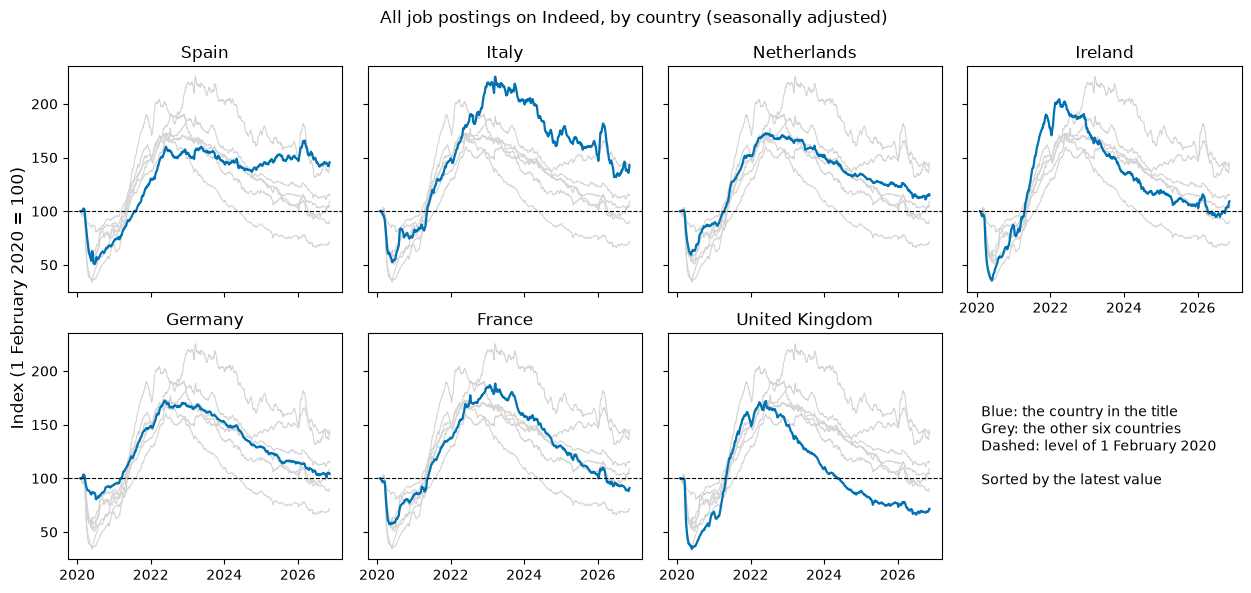

,lowest month,lowest,highest month,highest,highest before 2024,on 2026-11-13
jobcountry,,,,,,
ES,2020-06,53.9,2026-03,162.6,159.1,145.5
IT,2020-06,54.1,2023-01,218.9,218.9,142.8
NL,2020-05,61.1,2022-06,172.1,172.1,114.9
IE,2020-05,38.0,2022-03,202.1,202.1,109.2
DE,2020-07,81.9,2022-05,171.2,171.2,104.1
FR,2020-05,57.7,2023-01,185.4,185.4,90.9
GB,2020-06,36.3,2022-05,167.6,167.6,71.7


In [4]:
COUNTRY_NAMES = {"DE": "Germany", "ES": "Spain", "FR": "France", "GB": "United Kingdom",
                 "IE": "Ireland", "IT": "Italy", "NL": "Netherlands"}
index = indeed_totals.pivot(index="date", columns="jobcountry", values="indeed_job_postings_index_SA")
order = index.iloc[-1].sort_values(ascending=False).index  # countries sorted by their latest value

# one small plot per country: the country in blue, the other six in grey for comparison
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
for ax, country in zip(axes.flat, order):
    for other in index.columns.drop(country):
        ax.plot(index.index, index[other], color="lightgray", linewidth=0.8)
    ax.plot(index.index, index[country], color="#0072B2", linewidth=1.6)
    ax.axhline(100, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(COUNTRY_NAMES[country])
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# the last plot in the top row has no plot below it, so it needs its own year labels
axes[0, -1].tick_params(labelbottom=True)

legend_box = axes.flat[-1]
legend_box.axis("off")
legend_box.text(0.05, 0.5, "Blue: the country in the title\nGrey: the other six countries\nDashed: level of 1 February 2020\n\nSorted by the latest value",
                va="center", fontsize=10, transform=legend_box.transAxes)
fig.suptitle("All job postings on Indeed, by country (seasonally adjusted)")
fig.supylabel("Index (1 February 2020 = 100)")
fig.tight_layout()
plt.show()

# monthly means, so that one unusual day cannot decide the lowest or the highest point
monthly = index.resample("MS").mean()
pd.DataFrame({
    "lowest month": monthly.idxmin().dt.strftime("%Y-%m"),
    "lowest": monthly.min(),
    "highest month": monthly.idxmax().dt.strftime("%Y-%m"),
    "highest": monthly.max(),
    "highest before 2024": monthly.loc[:"2023"].max(),
    f"on {index.index.max().date()}": index.iloc[-1],
}).round(1).loc[order]

All seven countries follow a similar path. Job postings dropped sharply at the start of the COVID-19 pandemic: in every country the lowest month is between May and July 2020. Then they grew fast. Most countries had their highest month in 2022, France and Italy in January 2023. After that the index went down again. Spain is different: its highest month is March 2026 (162.6), but this is only a little above its level before 2024 (159.1).

The table uses monthly means, so that one unusual day cannot decide the lowest or the highest point.

On 13 November 2026, the United Kingdom (71.7) and France (90.9) are below the level of February 2020, while Spain (145.5) and Italy (142.8) are still far above it. These numbers are for **all** jobs; tech jobs follow in section 6.

Next, the sector table:

In [5]:
sectors_per_country = indeed_sectors.groupby("jobcountry")["display_name"].nunique()
print("Sectors per country:", sectors_per_country.to_dict())
print("Different sectors in all three countries:", indeed_sectors["display_name"].nunique())
print("Missing values in the sector table:", indeed_sectors.isna().sum().sum())

data_sectors = set(indeed_sectors["display_name"])
example_sectors = set(sector_examples["sector"])
print("Sectors in the data, but not in the example file:", sorted(data_sectors - example_sectors))
print("Sectors in the example file, but not in the data:", sorted(example_sectors - data_sectors))

Sectors per country: {'DE': 45, 'FR': 34, 'GB': 49}
Different sectors in all three countries: 52
Missing values in the sector table: 0
Sectors in the data, but not in the example file: ['Agriculture & Forestry', 'Chemical Engineering', 'Data & Analytics', 'IT Infrastructure, Operations & Support', 'IT Systems & Solutions', 'Mechanical Engineering', 'Real Estate', 'Social Science']
Sectors in the example file, but not in the data: ['IT Operations & Helpdesk', 'Information Design & Documentation', 'Mathematics']


Observations:

* Each country has its own list of sectors: 45 in Germany, 34 in France and 49 in the United Kingdom, 52 different names in total. So not every sector can be compared in all three countries.
* The file with example job titles does not match the data. Eight sectors have no examples, among them *Data & Analytics* and both *IT* sectors, and three sectors from the file do not appear in the data. It seems the file was not updated when the sectors changed. I use it only to understand what a sector means, never in a calculation.
* Neither table has missing values. The last day is 13 November 2026.
* Each country is compared with **its own** level in February 2020. A higher line means faster growth since then, not more jobs: the plot cannot tell us if Italy has more job ads than Germany.
* Indeed is one job site. The index shows how postings on Indeed change, not the total number of job ads in a country.

#### 2.2. Eurostat <a class="anchor" id="section_2_2"></a>

Eurostat gives four tables. Three of them have one value per country and year; the exchange rate table has one value per year. In all of them, `OBS_VALUE` is the number and `OBS_FLAG` is a note about its quality.

In [6]:
eurostat_files = {
    "ICT specialists": "eurostat_ict_specialists.csv",
    "ICT vacancies": "eurostat_ict_vacancies.csv",
    "Price levels": "eurostat_price_levels.csv",
    "USD rates": "eurostat_usd_rates.csv",
}
eurostat = {name: pd.read_csv(DATA_DIR / file) for name, file in eurostat_files.items()}


def eurostat_summary(table):
    """Rows, years, countries, missing values and flagged values of one Eurostat table."""
    countries = table.loc[table["geo"] != "EU27_2020", "geo"].nunique() if "geo" in table else "-"
    return {
        "rows": len(table),
        "years": f"{table['TIME_PERIOD'].min()}-{table['TIME_PERIOD'].max()}",
        "countries": countries,
        "missing values": table["OBS_VALUE"].isna().sum(),
        "flagged values": table["OBS_FLAG"].notna().sum(),
    }


pd.DataFrame({name: eurostat_summary(table) for name, table in eurostat.items()}).T

,rows,years,countries,missing values,flagged values
ICT specialists,1336,2004-2025,31,0,874
ICT vacancies,3779,2012-2024,30,39,67
Price levels,992,1995-2025,31,0,0
USD rates,55,1971-2025,-,0,0


In [7]:
all_flags = pd.concat(table["OBS_FLAG"] for table in eurostat.values()).dropna()
all_flags.value_counts().rename("values with this flag")

OBS_FLAG
e     586
be    166
b     126
u      41
d      16
bd      4
bu      2
Name: values with this flag, dtype: int64

A flag has one or more letters. Their meaning, from the official Eurostat list [10]:

| Letter | Meaning |
|---|---|
| b | break in time series: the method changed, so values before and after the break are not fully comparable |
| d | definition differs (see the metadata of the dataset) |
| e | estimated |
| u | low reliability |

Most flags are in the employment table: 874 of its 1336 values. The most common flag is *e*, so many of these numbers are estimates. For this project the *b* flags matter most, because a jump in a year with a break can come from a new method and not from a real change. Section 3 deals with this.

In [8]:
specialists = eurostat["ICT specialists"]
print("Last year for the United Kingdom:", specialists.loc[specialists["geo"] == "UK", "TIME_PERIOD"].max())

vacancies = eurostat["ICT vacancies"]
print("Years with vacancy data:", sorted(vacancies["TIME_PERIOD"].unique().tolist()))

# share of recruiting firms that had hard-to-fill ICT vacancies
hard_to_fill = vacancies[(vacancies["indic_is"] == "E_ITSPVAC2") & (vacancies["unit"] == "PC_ENT_ITSPRCR2")]
hard_to_fill_2024 = hard_to_fill[(hard_to_fill["TIME_PERIOD"] == 2024) & (hard_to_fill["geo"] != "EU27_2020")]
print("Countries with a 2024 value:", hard_to_fill_2024["OBS_VALUE"].notna().sum())
hard_to_fill_2024[hard_to_fill_2024["OBS_VALUE"].isna()][["geo", "OBS_VALUE", "OBS_FLAG"]]

Last year for the United Kingdom: 2019
Years with vacancy data: [2012, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2024]
Countries with a 2024 value: 27


,geo,OBS_VALUE,OBS_FLAG
2789,FR,NaN,u


Observations:

* The **United Kingdom** is in the employment table only until 2019, so for later years it cannot be linked to the other sources through Eurostat.
* The **vacancy table** has data only for some years, and since 2020 only for every second year (2020, 2022, 2024). Switzerland is missing completely, so this table has 30 countries instead of 31.
* For 2024, the share of firms with hard-to-fill ICT vacancies is known for 27 countries. Iceland and the United Kingdom have no row for 2024. France has a row, but no value: Eurostat marks it with *u* (low reliability) and does not publish the number.
* Price levels and exchange rates have no missing values and no flags. Both end in 2025.

#### 2.3. Stack Overflow Developer Survey <a class="anchor" id="section_2_3"></a>

There is one file per survey year. It contains only European respondents and only the columns listed in `build_snapshot.py`. Each row is one person.

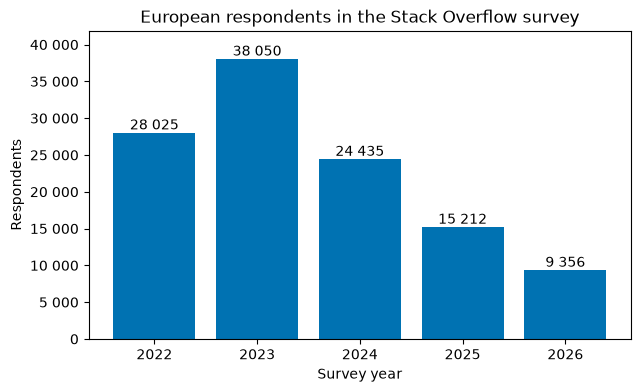

In [9]:
surveys = {year: pd.read_csv(DATA_DIR / f"stackoverflow_{year}.csv.gz", low_memory=False) for year in SURVEY_YEARS}

respondents = pd.Series({year: len(survey) for year, survey in surveys.items()})
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(respondents.index.astype(str), respondents.values, color="#0072B2")
ax.bar_label(bars, labels=[f"{value:,}".replace(",", " ") for value in respondents])
ax.set(title="European respondents in the Stack Overflow survey", xlabel="Survey year", ylabel="Respondents",
       ylim=(0, respondents.max() * 1.1))
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}".replace(",", " "))
plt.show()

In [10]:
all_columns = sorted(set().union(*(survey.columns for survey in surveys.values())))
pd.DataFrame({year: ["yes" if column in survey else "-" for column in all_columns]
              for year, survey in surveys.items()}, index=all_columns)

,2022,2023,2024,2025,2026
AISelect,-,yes,yes,yes,yes
Age,yes,yes,yes,yes,yes
CompFreq,yes,-,-,-,-
CompTotal,yes,yes,yes,yes,-
ConvertedCompYearly,yes,yes,yes,yes,yes
Country,yes,yes,yes,yes,yes
Currency,yes,yes,yes,yes,yes
DevType,yes,yes,yes,yes,-
EdLevel,yes,yes,yes,yes,-
Education,-,-,-,-,yes


The number of European respondents changes a lot: 38 050 in 2023, but only 9 356 in 2026. As written in section 1.4, this tells us something about the survey, not about the number of jobs.

The table shows which of the 24 kept columns exist in each year. The survey changed over time:

* Some questions only got a new name in 2026: `DevType` → `Role`, `RemoteWork` → `WorkSetting`, `EdLevel` → `Education`, `LanguageHaveWorkedWith` → `LanguagesHaveWorkedWith`.
* Some questions were dropped: `CompFreq` after 2022, `YearsCodePro` after 2024, `MainBranch` and `CompTotal` after 2025.
* Some questions are new: `AISelect` and `Industry` exist from 2023.

A new name does not guarantee the same answer options. Those are checked in section 3.

In [11]:
country_counts = pd.DataFrame({year: survey["Country"].value_counts() for year, survey in surveys.items()})
country_counts = country_counts.fillna(0).astype(int).sort_values(2026, ascending=False)
print("Countries in every year:", (country_counts > 0).all(axis=1).sum())
country_counts.head(8)

Countries in every year: 31


,2022,2023,2024,2025,2026
Country,,,,,
Germany,5395,7328,4947,3025,1983
United Kingdom of Great Britain and Northern Ireland,4190,5552,3224,2042,1374
France,2328,2933,2110,1409,794
Netherlands,1555,2383,1449,867,577
Poland,1732,2435,1534,888,527
Italy,1514,1835,1341,835,482
Spain,1521,1834,1123,717,453
Sweden,1020,1641,1016,616,370


In [12]:
smallest = country_counts.tail(5)
pd.concat([country_counts.loc[["Bulgaria"]], smallest])

,2022,2023,2024,2025,2026
Country,,,,,
Bulgaria,364,482,319,244,133
Estonia,141,234,110,70,35
Luxembourg,56,72,40,23,21
Iceland,28,57,31,13,13
Cyprus,61,84,63,39,11
Malta,39,46,29,19,11


In [13]:
pay_share = pd.Series({year: survey["ConvertedCompYearly"].notna().mean() for year, survey in surveys.items()})
print("Share of respondents who gave their pay:", (pay_share * 100).round(1).to_dict())

Share of respondents who gave their pay: {2022: 57.8, 2023: 57.5, 2024: 42.1, 2025: 71.7, 2026: 67.7}


Observations:

* All 31 countries appear in every survey year. Germany, the United Kingdom and France give the most answers.
* Small countries have very few answers. In 2026, Cyprus and Malta have 11 respondents each, and Bulgaria has 133. This is why every test needs at least 30 answers per group (section 1.3).
* The share of people who gave their pay changes from year to year, from 42.1% in 2024 to 71.7% in 2025. So the pay data is incomplete, and people who answer this question may differ from those who skip it.

#### 2.4. GitHub Innovation Graph <a class="anchor" id="section_2_4"></a>

For every country, quarter and language, `num_pushers` is the number of unique developers who made at least one git push to a repository in that language during the quarter [7].

In [14]:
# keep_default_na=False, because pandas would read the code "NA" (Namibia) as a missing value
languages = pd.read_csv(DATA_DIR / "github_languages.csv.gz", keep_default_na=False)
quarters = languages[["year", "quarter"]].drop_duplicates()
print("Quarters:", len(quarters), "| first:", tuple(quarters.iloc[0]), "| last:", tuple(quarters.iloc[-1]))
print("Countries:", languages["iso2_code"].nunique(), "| languages:", languages["language"].nunique())
print("Smallest number of developers in a row:", languages["num_pushers"].min())
overview(languages)

Quarters: 26 | first: (2020, 1) | last: (2026, 2)
Countries: 31 | languages: 295
Smallest number of developers in a row: 101


,type,missing,unique,example
num_pushers,int64,0,8519,6167
language,str,0,295,HTML
language_type,str,0,4,markup
iso2_code,str,0,31,AT
year,int64,0,7,2020
quarter,int64,0,4,1


In [15]:
last_quarter = languages[(languages["year"] == 2026) & (languages["quarter"] == 2)]
languages_per_country = last_quarter.groupby("iso2_code")["language"].nunique().sort_values()
print("Languages per country in 2026 Q2, fewest:", languages_per_country.head(4).to_dict())
print("Languages per country in 2026 Q2, most:", languages_per_country.tail(4).to_dict())

Languages per country in 2026 Q2, fewest: {'MT': 18, 'IS': 20, 'LU': 26, 'CY': 34}
Languages per country in 2026 Q2, most: {'NL': 169, 'FR': 196, 'GB': 213, 'DE': 242}


Observations:

* The table covers 26 quarters, from the first quarter of 2020 to the second quarter of 2026, and all 31 countries.
* The smallest value is 101. GitHub does not publish some numbers when fewer than 100 developers are behind them, to protect their privacy [7]. So a language used by only a few developers in a country is missing from the table, not zero.
* Because of this, small countries have short lists. In the second quarter of 2026, Malta has 18 languages and Germany 242. Comparisons between countries must take this into account.
* Besides programming languages, the table also counts markup and data formats such as HTML (column `language_type`).

#### 2.5. Summary <a class="anchor" id="section_2_5"></a>

In [16]:
summary = pd.DataFrame(
    [
        ("Indeed totals", len(indeed_totals), "day", indeed_totals["jobcountry"].nunique(), "jobcountry"),
        ("Indeed sectors", len(indeed_sectors), "day", indeed_sectors["jobcountry"].nunique(), "jobcountry"),
        ("Eurostat", sum(len(table) for table in eurostat.values()), "year",
         specialists.loc[specialists["geo"] != "EU27_2020", "geo"].nunique(), "geo"),
        ("Stack Overflow", sum(len(survey) for survey in surveys.values()), "survey year",
         len(country_counts), "Country"),
        ("GitHub", len(languages), "quarter", languages["iso2_code"].nunique(), "iso2_code"),
    ],
    columns=["source", "rows", "time unit", "countries", "country column"],
).set_index("source")
summary

,rows,time unit,countries,country column
source,,,,
Indeed totals,17346,day,7,jobcountry
Indeed sectors,317184,day,3,jobcountry
Eurostat,6162,year,31,geo
Stack Overflow,115078,survey year,31,Country
GitHub,61449,quarter,31,iso2_code


The sources differ in almost everything: time unit (day, year, quarter), period and the way they name countries (`GB` and `UK`, `GR` and `EL`, or full names in the survey). To join them, I need one common key for countries and one for time. Section 4 builds both.

### 3. Validation and cleaning <a class="anchor" id="chapter3"></a>

Section 2 showed what the files contain. Here I check that the data is correct and prepare it for the analysis. Three rules apply to every source:

* Each check that must always be true is an `assert`. If one fails, the notebook stops, so it never shows a result built on broken data.
* No value is changed. I only rename columns and answer options or remove rows, and every removal is counted.
* The rules for the tests were fixed in section 1.3. This section only applies them.

#### 3.1. Indeed <a class="anchor" id="section_3_1"></a>

Both tables are checked in the same way: no day appears twice, no day is missing, every series equals 100 on 1 February 2020, and no value is 0 or negative.

In [17]:
for table, keys in [(indeed_totals, ["jobcountry"]), (indeed_sectors, ["jobcountry", "display_name"])]:
    values = table.filter(like="index")
    assert not table.duplicated(["date"] + keys).any(), "a day appears twice"
    days = table.groupby(keys)["date"].agg(["min", "max", "count"])
    assert ((days["max"] - days["min"]).dt.days + 1 == days["count"]).all(), "a series has missing days"
    assert (values[table["date"] == "2020-02-01"] == 100).all().all(), "a series is not 100 on the base day"
    assert (values > 0).all().all(), "an index value is 0 or negative"
print("Indeed: all checks passed")

Indeed: all checks passed


In [18]:
TECH_SECTORS = ["Software Development", "Data & Analytics", "IT Systems & Solutions",
                "IT Infrastructure, Operations & Support"]

indeed_tech = indeed_sectors[indeed_sectors["display_name"].isin(TECH_SECTORS)]
indeed_tech.groupby(["display_name", "jobcountry"]).size().unstack(fill_value=0).rename_axis(index="days of data")

jobcountry,DE,FR,GB
days of data,,,
Data & Analytics,2478,0,2478
"IT Infrastructure, Operations & Support",2478,2478,2478
IT Systems & Solutions,2478,2478,2478
Software Development,2478,2478,2478


All four checks pass.

Indeed has four sectors for tech jobs, listed in `TECH_SECTORS`. There is no separate sector for AI jobs. The table above shows that France has no *Data & Analytics* sector, so every result for this sector uses only Germany and the United Kingdom. I chose the four sectors by their names. The file with example job titles has no examples for them (section 2.1), so I cannot show which job titles each sector includes.

#### 3.2. Eurostat <a class="anchor" id="section_3_2"></a>

The checks: every share is between 0 and 100, a value is missing only when Eurostat marks it with *u*, and price levels and exchange rates are always above 0.

The vacancy table allows one more test of its own consistency. Among firms that tried to recruit ICT specialists, some had hard-to-fill vacancies and the others had none, so in 2024 the two shares must add up to 100 in each country.

In [19]:
for name in ["ICT specialists", "ICT vacancies"]:
    table = eurostat[name]
    shares = table.loc[table["unit"].str.startswith("PC_"), "OBS_VALUE"].dropna()
    assert shares.between(0, 100).all(), f"{name}: a share is outside 0-100"
    missing_flags = table.loc[table["OBS_VALUE"].isna(), "OBS_FLAG"]
    assert missing_flags.str.contains("u", na=False).all(), f"{name}: a value is missing without the flag u"
for name in ["Price levels", "USD rates"]:
    assert (eurostat[name]["OBS_VALUE"] > 0).all(), f"{name}: a value is missing, 0 or negative"

# shares of recruiting firms WITH and WITHOUT hard-to-fill vacancies must add up to 100
shares_2024 = vacancies[(vacancies["unit"] == "PC_ENT_ITSPRCR2") & (vacancies["TIME_PERIOD"] == 2024)
                        & (vacancies["geo"] != "EU27_2020")]
with_without = shares_2024.pivot(index="geo", columns="indic_is", values="OBS_VALUE")[["E_ITSPVAC2", "E_ITSPVAC2X"]]
with_without = with_without.dropna()
assert ((with_without.sum(axis=1) - 100).abs() <= 0.1).all(), "the two shares do not add up to 100"
print("Eurostat: all checks passed. Countries with both shares in 2024:", len(with_without))

Eurostat: all checks passed. Countries with both shares in 2024: 27


In [20]:
has_break = specialists["OBS_FLAG"].str.contains("b", na=False)
breaks = specialists[has_break & (specialists["unit"] == "PC_EMP") & (specialists["geo"] != "EU27_2020")]
recent_breaks = breaks[breaks["TIME_PERIOD"] >= 2019].groupby("TIME_PERIOD")["geo"].agg(["count", "unique"])
recent_breaks["unique"] = recent_breaks["unique"].map(lambda codes: ", ".join(sorted(codes)) if len(codes) <= 5 else "...")
in_2021 = set(specialists.loc[specialists["TIME_PERIOD"] == 2021, "geo"]) - {"EU27_2020"}
assert in_2021 == set(breaks.loc[breaks["TIME_PERIOD"] == 2021, "geo"])
print("Countries with data for 2021:", len(in_2021), "- all of them have a break in 2021")
recent_breaks.rename(columns={"count": "countries with a break", "unique": "which"})

Countries with data for 2021: 30 - all of them have a break in 2021


,countries with a break,which
TIME_PERIOD,,
2019,2,"BG, PL"
2020,2,"DE, IS"
2021,30,...
2023,1,DK
2024,1,BG


In [21]:
hard_to_fill_2024[hard_to_fill_2024["OBS_FLAG"].notna()][["geo", "OBS_VALUE", "OBS_FLAG"]]

,geo,OBS_VALUE,OBS_FLAG
2789,FR,NaN,u
2933,SE,53.03,b


All checks pass. In 2024 the two vacancy shares add up to 100 in all 27 countries that have both values.

The breaks need more attention. In the employment table, **every country with data for 2021 has a break in that year**. Eurostat explains why: from 2021 the Labour Force Survey follows a new EU regulation (Regulation (EU) 2019/1700), which led to method changes in some countries, so all data for 2021 are marked as a break [13]. Germany also has a break in 2020. A change between 2020 and 2021 can therefore come from the new method and not from more ICT jobs. There are no corrected values, so I keep the published ones. However, I do not read the change across 2021 as real growth, and the plots of this table in section 6 mark the year 2021.

In the 2024 vacancy data, Sweden has a break as well. A break means that the method changed compared with earlier years. H6 compares countries only within 2024, so Sweden stays in the test. France has no value and is left out, as planned in section 1.3.

#### 3.3. Stack Overflow Developer Survey <a class="anchor" id="section_3_3"></a>

First, the four questions that got new names in 2026 go back to their old names (section 2.3). Then I check that every `ResponseId` is unique and count the rows that are identical to another row in all other columns.

In [22]:
# 2026 uses new names for four questions; I go back to the old names, so the same code works for every year
COLUMN_RENAMES = {"Role": "DevType", "WorkSetting": "RemoteWork", "Education": "EdLevel",
                  "LanguagesHaveWorkedWith": "LanguageHaveWorkedWith"}
surveys = {year: survey.rename(columns=COLUMN_RENAMES) for year, survey in surveys.items()}

for year, survey in surveys.items():
    assert survey["ResponseId"].is_unique, f"{year}: a ResponseId appears twice"
    assert {"DevType", "RemoteWork", "LanguageHaveWorkedWith", "ConvertedCompYearly"} <= set(survey.columns), year

identical = {}
for year, survey in surveys.items():
    same = survey.drop(columns="ResponseId").duplicated(keep=False)
    identical[year] = {
        "rows": len(survey),
        "rows identical to another row": same.sum(),
        "of them with pay": survey.loc[same, "ConvertedCompYearly"].notna().sum(),
    }
pd.DataFrame(identical)

,2022,2023,2024,2025,2026
rows,28025,38050,24435,15212,9356
rows identical to another row,16,12,6,10,4
of them with pay,0,0,2,6,0


Every `ResponseId` is unique. Identical rows are rare: at most 16 in a year. Most of them have no pay and many empty answers, often from students, so two people can easily give the same short answers. Only 2025 has identical rows with pay: three pairs, 6 of 15 212 rows. They may be one person who answered twice, but the data cannot prove it, so I keep all rows.

Next, the answers about remote work:

In [23]:
# in 2022 two answers had other names, with the same meaning (section 1.3)
REMOTE_LABELS_2022 = {"Fully remote": "Remote", "Full in-person": "In-person"}
surveys[2022] = surveys[2022].assign(RemoteWork=surveys[2022]["RemoteWork"].replace(REMOTE_LABELS_2022))

assert set(surveys[2022]["RemoteWork"].dropna()) == set(surveys[2024]["RemoteWork"].dropna())

remote_options = pd.DataFrame({year: survey["RemoteWork"].value_counts() for year, survey in surveys.items()})
# Remote first, In-person last; "-" means that the answer did not exist in that year
order = ["Remote", "Your choice (very flexible, you can come in when you want or just as needed)",
         "Hybrid (some in-person, leans heavy to flexibility)", "Hybrid (some remote, some in-person)",
         "Hybrid (some remote, leans heavy to in-person)", "In-person"]
assert set(order) == set(remote_options.index)
remote_options.loc[order].map(lambda count: "-" if pd.isna(count) else int(count))

,2022,2023,2024,2025,2026
RemoteWork,,,,,
Remote,8037,10916,6483,2887,2291
"Your choice (very flexible, you can come in when you want or just as needed)",-,-,-,2032,1312
"Hybrid (some in-person, leans heavy to flexibility)",-,-,-,2770,1662
"Hybrid (some remote, some in-person)",12924,17090,11177,-,-
"Hybrid (some remote, leans heavy to in-person)",-,-,-,2897,1933
In-person,2844,4742,3563,1638,1011


After the two answers from 2022 get their new names, 2022 and 2024 have exactly the same three options, and the `assert` checks this. So H5 can compare them as planned.

In 2025 the question changed: it now has five options, two of them different kinds of *Hybrid*. These cannot be mapped to the old three without guessing, so 2025 and 2026 are only described in section 8, not tested.

In [24]:
usd_per_eur = eurostat["USD rates"].set_index("TIME_PERIOD")["OBS_VALUE"]

rates = {}
for year in [2022, 2023, 2024, 2025]:  # CompTotal is not in the 2026 file
    survey = surveys[year]
    in_euro = survey[survey["Currency"].str.startswith("EUR", na=False) & (survey["CompTotal"] > 0)]
    if year == 2022:
        in_euro = in_euro[in_euro["CompFreq"] == "Yearly"]  # 2022 also has monthly and weekly answers
    implied = (in_euro["ConvertedCompYearly"] / in_euro["CompTotal"]).dropna().round(3)
    most_common = implied.mode()[0]
    rates[year] = {
        "answers in EUR": len(implied),
        "USD per EUR used by the survey": most_common,
        "share of answers with this rate (%)": round(100 * (implied == most_common).mean(), 1),
        "Eurostat yearly average": usd_per_eur[year],
        "difference (%)": round(100 * (most_common / usd_per_eur[year] - 1), 1),
    }
pd.DataFrame(rates).T.astype({"answers in EUR": int})

,answers in EUR,USD per EUR used by the survey,share of answers with this rate (%),Eurostat yearly average,difference (%)
2022,5883,1.066,99.6,1.0530,1.2
2023,13049,1.071,99.7,1.0813,-1.0
2024,6343,1.074,99.7,1.0824,-0.8
2025,6721,1.160,99.2,1.1300,2.7


Section 2 left one question open: which exchange rate does Stack Overflow use for `ConvertedCompYearly`? The documentation does not say, but the data can show it. For people paid in euros, `ConvertedCompYearly` divided by `CompTotal` is the number of US dollars per euro that the survey used.

The 2026 file has no `CompTotal`, so this check covers 2022–2025. In each of these years, more than 99% of the answers give the same rate. So the survey uses **one fixed rate for the whole year**. Most of the other values belong to very small amounts, where rounding to whole dollars changes the ratio. This rate is not the Eurostat yearly average: the difference is between −1.0% and +2.7%.

What this means for formula (4): for a person paid in euros, $w_{\text{USD}} / r_t$ equals the amount the person gave, multiplied by (survey rate / Eurostat rate). In 2025, all euro salaries therefore come out 2.7% higher than the amounts people entered. Within one year, this factor is the same for everyone paid in euros, so the order of euro countries does not change. Other currencies have their own survey rates, which I did not check, so small shifts between currencies are possible. I keep formula (4) as fixed in section 1.3 and list this point in section 10.

In [25]:
EMPLOYEES = {2022: "Employed, full-time", 2023: "Employed, full-time", 2024: "Employed, full-time",
             2025: "Employed", 2026: "Employed"}


def pay_sample(survey, year):
    """Employees with pay above 0, without the lowest and the highest 1% of the year (rules in section 1.3)."""
    employees = survey[survey["Employment"] == EMPLOYEES[year]]
    paid = employees[employees["ConvertedCompYearly"] > 0]
    low, high = paid["ConvertedCompYearly"].quantile([0.01, 0.99])
    return paid[paid["ConvertedCompYearly"].between(low, high)]


pay = {year: pay_sample(survey, year) for year, survey in surveys.items()}

steps = {}
for year, survey in surveys.items():
    employees = survey[survey["Employment"] == EMPLOYEES[year]]
    steps[year] = {
        "respondents": len(survey),
        "employees": len(employees),
        "employees with pay above 0": (employees["ConvertedCompYearly"] > 0).sum(),
        "after removing 1% at each end": len(pay[year]),
        "lowest pay kept (USD)": pay[year]["ConvertedCompYearly"].min(),
        "highest pay kept (USD)": pay[year]["ConvertedCompYearly"].max(),
    }
pd.DataFrame(steps).astype(int)

,2022,2023,2024,2025,2026
respondents,28025,38050,24435,15212,9356
employees,16874,23048,14934,11133,6643
employees with pay above 0,13061,17332,7552,8910,5197
after removing 1% at each end,12799,16984,7406,8735,5093
lowest pay kept (USD),11100,3538,3805,2204,1891
highest pay kept (USD),1182240,235863,254776,290037,292594


In [26]:
for year in [2022, 2023, 2024]:
    employment = surveys[year]["Employment"]
    also_other = (employment.str.contains("Employed, full-time", regex=False, na=False)
                  & (employment != "Employed, full-time")).sum()
    print(f"{year}: full-time employees who also chose another answer (left out): {also_other}")

2022: full-time employees who also chose another answer (left out): 2261
2023: full-time employees who also chose another answer (left out): 2909
2024: full-time employees who also chose another answer (left out): 1978


The function `pay_sample` applies the pay rules from section 1.3, and the table shows how many answers are left after each step:

* In 2022–2024, people could choose more than one employment answer. Only those whose answer is exactly "Employed, full-time" are counted. Between 1 978 and 2 909 people a year chose it together with another answer, for example freelancing or studying. They are left out, because part of their income may come from other work.
* In 2024 only about half of the employees gave their pay (7 552 of 14 934), the lowest share of all years.
* Removing 1% at each end does not remove every strange value. In 2022 the highest pay kept is still 1 182 240 USD a year, while in the other years it is between 236 000 and 293 000. The lowest values kept in 2023–2026, between 1 891 and 3 805 USD a year, are also very low for a full-time job. This is why the analysis uses medians and rank-based tests, which a few extreme values cannot move much. Neither H4 nor H6 uses 2022.

#### 3.4. GitHub Innovation Graph <a class="anchor" id="section_3_4"></a>

The checks: no row appears twice, no value is below GitHub's privacy limit of 100 developers, all 31 countries are present in every quarter, and each language has only one type.

In [27]:
assert not languages.duplicated(["iso2_code", "year", "quarter", "language"]).any(), "a row appears twice"
assert (languages["num_pushers"] >= 100).all(), "a value below the privacy limit"
assert (languages.groupby(["year", "quarter"])["iso2_code"].nunique() == 31).all(), "a quarter misses a country"
assert (languages.groupby("language")["language_type"].nunique() == 1).all(), "a language has two types"
print("GitHub: all checks passed")
languages["language_type"].value_counts().rename("rows")

GitHub: all checks passed


language_type
programming    50139
markup         10969
data             250
prose             91
Name: rows, dtype: int64

All checks pass. Most rows are programming languages. The others are markup languages such as HTML, data formats and prose. The survey also counts HTML/CSS and SQL as languages, so I keep all types here and decide in section 7 which ones to compare.

#### 3.5. Summary <a class="anchor" id="section_3_5"></a>

| Source | Checks that pass | Decisions |
|---|---|---|
| Indeed | no repeated or missing days, base day = 100, all values above 0 | four tech sectors; *Data & Analytics* only for Germany and the United Kingdom |
| Eurostat | shares between 0 and 100, missing values only with flag *u*, 2024 vacancy shares add up to 100 | published values kept; changes across the 2021 break are not read as growth; in H6 Sweden stays and France is left out |
| Stack Overflow | unique `ResponseId`, identical rows counted and kept | old names for the 2026 questions; 2022 remote answers renamed; 2025–2026 remote answers only described; pay rules from section 1.3 applied; exchange rate difference noted for section 10 |
| GitHub | no repeated rows, privacy limit, 31 countries in every quarter, one type per language | all language types kept until section 7 |

Each source still names countries in its own way. Section 4 gives them one common key and joins them.

### 4. Consolidation <a class="anchor" id="chapter4"></a>

To join the sources, they need the same keys. This project uses two: the **country**, as a two-letter ISO 3166 code, and the **year**. This section also puts every survey role into one of the six groups from section 1.3 and computes real pay with formula (4).

#### 4.1. One code for every country <a class="anchor" id="section_4_1"></a>

Indeed and GitHub already use ISO codes. Eurostat does too, with two exceptions: `EL` for Greece and `UK` for the United Kingdom. The survey writes full names, and for the United Kingdom it uses the long official name. The function `add_country` gives every table the same `country` column and stops if a name has no code.

In [28]:
# the 31 countries from section 1.4: ISO 3166 code -> short name
COUNTRIES = {
    "AT": "Austria", "BE": "Belgium", "BG": "Bulgaria", "HR": "Croatia", "CY": "Cyprus", "CZ": "Czech Republic",
    "DK": "Denmark", "EE": "Estonia", "FI": "Finland", "FR": "France", "DE": "Germany", "GR": "Greece",
    "HU": "Hungary", "IE": "Ireland", "IT": "Italy", "LV": "Latvia", "LT": "Lithuania", "LU": "Luxembourg",
    "MT": "Malta", "NL": "Netherlands", "PL": "Poland", "PT": "Portugal", "RO": "Romania", "SK": "Slovakia",
    "SI": "Slovenia", "ES": "Spain", "SE": "Sweden", "GB": "United Kingdom", "CH": "Switzerland",
    "NO": "Norway", "IS": "Iceland",
}
# only these names differ from the codes and short names above
EUROSTAT_TO_ISO = {"EL": "GR", "UK": "GB"}
SURVEY_TO_ISO = {name: code for code, name in COUNTRIES.items() if code != "GB"}
SURVEY_TO_ISO["United Kingdom of Great Britain and Northern Ireland"] = "GB"


def add_country(table, column, to_iso):
    """Copy of the table with a column 'country' (ISO code). Stops if a value has no code."""
    country = table[column].map(lambda value: to_iso.get(value, value))
    unknown = set(country) - set(COUNTRIES) - {"EU27_2020"}
    assert not unknown, f"no ISO code for {unknown}"
    return table.assign(country=country)


indeed_totals = add_country(indeed_totals, "jobcountry", {})
indeed_tech = add_country(indeed_tech, "jobcountry", {})
eurostat = {name: add_country(table, "geo", EUROSTAT_TO_ISO) if "geo" in table else table
            for name, table in eurostat.items()}
surveys = {year: add_country(survey, "Country", SURVEY_TO_ISO) for year, survey in surveys.items()}
pay = {year: add_country(sample, "Country", SURVEY_TO_ISO) for year, sample in pay.items()}
languages = add_country(languages, "iso2_code", {})
print("Every country name in every source has an ISO code")

Every country name in every source has an ISO code


In [29]:
specialists_2020 = eurostat["ICT specialists"].query("TIME_PERIOD >= 2020")
vacancies_2024 = eurostat["ICT vacancies"].query(
    "indic_is == 'E_ITSPVAC2' and unit == 'PC_ENT_ITSPRCR2' and TIME_PERIOD == 2024 and OBS_VALUE.notna()")
covered = {
    "Indeed, all jobs": indeed_totals["country"],
    "Indeed, tech sectors": indeed_tech["country"],
    "Eurostat, ICT specialists 2020-2025": specialists_2020["country"],
    "Eurostat, hard-to-fill vacancies 2024": vacancies_2024["country"],
    "Eurostat, price levels": eurostat["Price levels"]["country"],
    "Stack Overflow, every year": pd.concat(survey["country"] for survey in surveys.values()),
    "GitHub": languages["country"],
}
coverage = {}
for source, codes in covered.items():
    present = set(codes) - {"EU27_2020"}
    missing = sorted(set(COUNTRIES) - present)
    coverage[source] = {"countries": len(present),
                        "missing": ", ".join(missing) if len(missing) <= 8 else f"all except {', '.join(sorted(present))}"}
pd.DataFrame(coverage).T

,countries,missing
"Indeed, all jobs",7,"all except DE, ES, FR, GB, IE, IT, NL"
"Indeed, tech sectors",3,"all except DE, FR, GB"
"Eurostat, ICT specialists 2020-2025",30,GB
"Eurostat, hard-to-fill vacancies 2024",27,"CH, FR, GB, IS"
"Eurostat, price levels",31,
"Stack Overflow, every year",31,
GitHub,31,


Before building the snapshot, I also searched the full survey files for other spellings of these 31 countries, for example "Czechia" instead of "Czech Republic". There were none, so the snapshot did not lose any answers by keeping only these names. This check used the raw files, which are not in the repository.

The table shows which countries each source covers. All 31 are only in the price levels, the survey and GitHub. The United Kingdom has no Eurostat employment data after 2019, and Switzerland, France, the United Kingdom and Iceland have no vacancy value for 2024 (section 2.2).

#### 4.2. One row per country and year <a class="anchor" id="section_4_2"></a>

Eurostat and the survey already give one value per year. For Indeed I take the mean of all days in a year; for 2026 these are the days from 1 January to 13 November. The function `by_country_year` turns a table into a series with the key (country, year) and checks that no key appears twice.

All series then go into one table, `panel`, with one row for every country and every year from 2020 to 2026. A row stays even when a source has no value for it, so the gaps are visible instead of quietly removed.

In [30]:
def by_country_year(table, value="OBS_VALUE"):
    """One value per (country, year) as a Series; stops if a pair appears twice."""
    series = table.rename(columns={"TIME_PERIOD": "year"}).set_index(["country", "year"])[value]
    assert series.index.is_unique, "a (country, year) pair appears twice"
    return series


indeed_yearly = (indeed_totals.assign(year=indeed_totals["date"].dt.year)
                 .groupby(["country", "year"])["indeed_job_postings_index_SA"].mean())
respondents_by_country = pd.concat({year: survey["country"].value_counts() for year, survey in surveys.items()},
                                   names=["year", "country"]).swaplevel()

panel = pd.concat({
    "ICT specialists (% of employment)":
        by_country_year(eurostat["ICT specialists"].query("unit == 'PC_EMP'")),
    "firms with hard-to-fill ICT vacancies (%)":
        by_country_year(eurostat["ICT vacancies"].query("indic_is == 'E_ITSPVAC2' and unit == 'PC_ENT_ITSPRCR2'")),
    "price level (EU27 = 100)": by_country_year(eurostat["Price levels"]),
    "Indeed, all jobs (yearly mean)": indeed_yearly,
    "survey respondents": respondents_by_country,
}, axis=1)

# one row for every country and year from 2020 to 2026, also where a source has no value
years = range(2020, 2027)
panel = panel.reindex(pd.MultiIndex.from_product([sorted(COUNTRIES), years], names=["country", "year"]))
assert panel.index.is_unique

panel.notna().groupby(level="year").sum().T.rename_axis(columns="countries with a value in")

countries with a value in,2020,2021,2022,2023,2024,2025,2026
ICT specialists (% of employment),30,30,30,30,30,29,0
firms with hard-to-fill ICT vacancies (%),30,0,28,0,27,0,0
price level (EU27 = 100),31,31,31,31,31,31,0
"Indeed, all jobs (yearly mean)",7,7,7,7,7,7,7
survey respondents,0,0,31,31,31,31,31


The table counts, for every year, the countries that have a value. It is also the report of what does not match:

* The sources overlap only in a few years. The survey starts in 2022, Eurostat ends in 2025, and the vacancy data in 2024.
* Vacancy data exists only every second year (2020, 2022, 2024).
* Indeed covers 7 countries, and its tech sectors only 3. So Q2, which compares job postings with ICT employment, can only use Germany and France: the United Kingdom has no Eurostat data after 2019.
* ICT employment for 2025 has 29 countries, because the data for Iceland ends in 2024.

GitHub is not in this table, because it has one value per language. Section 7 joins it with the survey by country, year and language.

#### 4.3. Role groups <a class="anchor" id="section_4_3"></a>

Since 2023, a person can choose only one role. In 2022 people could choose several roles, so a person could not be put into a single group. For this reason, role groups start in 2023; H3 compares 2023 with 2026, and H4 uses 2025.

The table shows the group of every answer and the survey years in which the answer exists. Students and retired people are not counted (section 1.3). The `assert` checks make sure that every answer has exactly one group, so an unknown answer in a new file would stop the notebook.

In [31]:
ROLE_GROUPS = {
    "Software development": [
        "Developer, full-stack", "Developer, back-end", "Developer, front-end",
        "Developer, desktop or enterprise applications", "Developer, mobile",
        "Developer, embedded applications or devices", "Developer, game or graphics", "Developer, QA or test",
        "Software engineer", "Blockchain",
        "Solutions engineer, implementation engineer, or forward-deployed engineer",
    ],
    "Data & AI": [
        "Engineer, data", "Data engineer", "Data scientist or machine learning specialist", "Data scientist",
        "AI/ML engineer", "Developer, AI", "Developer, AI apps or physical AI", "Data or business analyst",
        "Database administrator", "Database administrator or engineer",
    ],
    "Cloud & operations": [
        "DevOps specialist", "DevOps engineer or professional", "Cloud infrastructure engineer",
        "System administrator", "Engineer, site reliability", "Site reliability engineer", "Platform engineer",
        "Support engineer or analyst",
    ],
    "Security": ["Security professional", "Cybersecurity or InfoSec professional"],
    "Architecture & management": [
        "Architect, software or solutions", "Engineering manager", "Project manager", "Product manager",
        "Senior Executive (C-Suite, VP, etc.)", "Senior executive (C-suite, VP, etc.)",
        "Founder, technology or otherwise", "Founder or entrepreneur",
    ],
    "Other": [
        "Other (please specify):", "Other", "Academic researcher", "Research & Development role", "Scientist",
        "Applied scientist", "Educator", "Educator or instructor", "Designer",
        "UX, Research Ops or UI design professional", "UX, research, or UI design professional",
        "Hardware Engineer", "Hardware engineer", "Developer Experience", "Developer Advocate",
        "Developer advocate or developer relations professional", "Marketing or sales professional",
        "Marketing/Sales professional", "Financial analyst or engineer",
        "Technical writer or documentation professional",
    ],
}
NOT_COUNTED = ["Student", "Retired"]  # section 1.3
ROLE_TO_GROUP = {answer: group for group, answers in ROLE_GROUPS.items() for answer in answers}
assert len(ROLE_TO_GROUP) == sum(len(answers) for answers in ROLE_GROUPS.values()), "an answer is in two groups"

ROLE_YEARS = [2023, 2024, 2025, 2026]  # one answer per person; in 2022 people could choose several roles
answers = {year: set(surveys[year]["DevType"].dropna()) for year in ROLE_YEARS}
all_answers = set().union(*answers.values())
assert all_answers <= set(ROLE_TO_GROUP) | set(NOT_COUNTED), f"no group for {all_answers - set(ROLE_TO_GROUP)}"
assert set(ROLE_TO_GROUP) <= all_answers, "a mapped answer does not appear in any year"

role_table = pd.DataFrame(
    {"survey years": [", ".join(str(year) for year in ROLE_YEARS if answer in answers[year]) for answer in ROLE_TO_GROUP]},
    index=pd.MultiIndex.from_tuples([(group, answer) for answer, group in ROLE_TO_GROUP.items()],
                                    names=["group", "survey answer"]),
)
role_table

survey years
group                     survey answer                                                             
Software development      Developer, full-stack                               2023, 2024, 2025, 2026
                          Developer, back-end                                 2023, 2024, 2025, 2026
                          Developer, front-end                                2023, 2024, 2025, 2026
                          Developer, desktop or enterprise applications       2023, 2024, 2025, 2026
                          Developer, mobile                                   2023, 2024, 2025, 2026
                          Developer, embedded applications or devices         2023, 2024, 2025, 2026
                          Developer, game or graphics                         2023, 2024, 2025, 2026
                          Developer, QA or test                               2023, 2024, 2025, 2026
                          Software engineer                                                     2026
                          Blockchain                                                      2023, 2024
                          Solutions engineer, implementation engineer, or...                    2026
Data & AI                 Engineer, data                                                        2023
                          Data engineer                                             2024, 2025, 2026
                          Data scientist or machine learning specialist                   2023, 2024
                          Data scientist                                                  2025, 2026
                          AI/ML engineer                                                  2025, 2026
                          Developer, AI                                                         2024
                          Developer, AI apps or physical AI                               2025, 2026
                          Data or business analyst                            2023, 2024, 2025, 2026
                          Database administrator                                          2023, 2024
                          Database administrator or engineer                              2025, 2026
Cloud & operations        DevOps specialist                                               2023, 2024
                          DevOps engineer or professional                                 2025, 2026
                          Cloud infrastructure engineer                       2023, 2024, 2025, 2026
                          System administrator                                2023, 2024, 2025, 2026
                          Engineer, site reliability                                      2023, 2024
                          Site reliability engineer                                             2026
                          Platform engineer                                                     2026
                          Support engineer or analyst                                     2025, 2026
Security                  Security professional                                           2023, 2024
                          Cybersecurity or InfoSec professional                           2025, 2026
Architecture & management Architect, software or solutions                                2025, 2026
                          Engineering manager                                 2023, 2024, 2025, 2026
                          Project manager                                     2023, 2024, 2025, 2026
                          Product manager                                     2023, 2024, 2025, 2026
                          Senior Executive (C-Suite, VP, etc.)                            2023, 2024
                          Senior executive (C-suite, VP, etc.)                            2025, 2026
                          Founder, technology or otherwise                                      2025
                          Founder or entrepreneu

In [32]:
def add_role_group(table):
    """Copy of the table with the role group of each person (empty for students, retired people and no answer)."""
    return table.assign(role_group=table["DevType"].map(ROLE_TO_GROUP))


surveys.update({year: add_role_group(surveys[year]) for year in ROLE_YEARS})
pay.update({year: add_role_group(pay[year]) for year in ROLE_YEARS})

new_answers = {year: sorted(answers[year] - answers[year - 1]) for year in ROLE_YEARS[1:]}
for year, names in new_answers.items():
    print(f"New answers in {year}: {len(names)}")

New answers in 2024: 2
New answers in 2025: 14
New answers in 2026: 12


Some decisions were not obvious:

* AI developers are in *Data & AI*, although they also write software, because their work is closest to the AI and machine learning roles.
* Database administrators are in *Data & AI*, support engineers in *Cloud & operations* and founders in *Architecture & management*. Applied scientists are in *Other*, together with the other scientists.

The list of roles changed a lot: 2 new answers in 2024, 14 in 2025 and 12 in 2026. Many of them are only new spellings, such as *Engineer, data* → *Data engineer*. One change matters for H3: *Architect, software or solutions* exists only from 2025. In 2023, architects had to pick another answer or skip the question. So if *Architecture & management* has a larger share in 2026 than in 2023, part of the difference may come from the new answer and not from more architects. The test in section 7 cannot separate these two effects, and the discussion of its result has to say so.

#### 4.4. Real pay <a class="anchor" id="section_4_4"></a>

Formula (4) joins two sources in every pay answer: the survey gives $w_{\text{USD}}$, and Eurostat gives the exchange rate $r_t$ and the price level of the person's country. Here *real* means adjusted for the different price levels of the countries, not for inflation over time. Eurostat uses the word in the same way, for example in its indicator *Real expenditure (in PPS)* [5]. The function `add_real_pay` adds the column `real_pay` and stops if a country has no price level. The cell below repeats the calculation by hand for one answer, and an `assert` checks that the code gives the same number.

In [33]:
price_levels = by_country_year(eurostat["Price levels"])


def add_real_pay(sample, year):
    """Formula (4): yearly pay in euros at EU-average prices. 2026 uses the 2025 rate and price levels."""
    data_year = min(year, 2025)
    pli = sample["country"].map(price_levels.xs(data_year, level="year"))
    assert pli.notna().all(), f"{year}: a country has no price level"
    return sample.assign(real_pay=sample["ConvertedCompYearly"] / usd_per_eur[data_year] / (pli / 100))


pay = {year: add_real_pay(sample, year) for year, sample in pay.items()}

# formula (4) by hand for the first Bulgarian answer of 2025
example = pay[2025][pay[2025]["country"] == "BG"].iloc[0]
w_usd, r, pli = example["ConvertedCompYearly"], usd_per_eur[2025], price_levels["BG", 2025]
print(f"w_USD = {w_usd:.0f}, r = {r}, PLI = {pli}  ->  ({w_usd:.0f} / {r}) / ({pli} / 100) = {w_usd / r / (pli / 100):.0f}")
assert abs(example["real_pay"] - w_usd / r / (pli / 100)) < 1e-6

w_USD = 35584, r = 1.13, PLI = 60.0  ->  (35584 / 1.13) / (60.0 / 100) = 52484


In [34]:
# H6 sample, counted again from the joined data (section 1.3 says 24 countries)
answers_2024 = pay[2024]["country"].value_counts()
h6_countries = sorted(set(vacancies_2024["country"]) & set(answers_2024[answers_2024 >= 30].index))
print("Countries for H6:", len(h6_countries))
print("Left out:", {code: "fewer than 30 pay answers" if code in vacancies_2024["country"].values else "no Eurostat value"
                    for code in sorted(set(COUNTRIES) - set(h6_countries))})
assert len(h6_countries) == 24

Countries for H6: 24
Left out: {'CH': 'no Eurostat value', 'CY': 'fewer than 30 pay answers', 'FR': 'no Eurostat value', 'GB': 'no Eurostat value', 'IS': 'no Eurostat value', 'LU': 'fewer than 30 pay answers', 'MT': 'fewer than 30 pay answers'}


In the example, a person in Bulgaria earned 35 584 USD in 2025, which is 31 490 euros (35 584 / 1.13). Prices in Bulgaria are 60% of the EU average, so this pay buys as much as 52 484 euros would buy at average EU prices.

The last cell counts the H6 sample again, this time from the joined data. The result is 24 countries, the same number as in section 1.3. Seven countries are left out: Cyprus, Luxembourg and Malta have fewer than 30 pay answers, while Switzerland, France, the United Kingdom and Iceland have no Eurostat value for 2024.

All sources now share the same keys. Section 5 describes the statistical methods, and sections 6–8 use the joined tables.

### 5. Statistical methods <a class="anchor" id="chapter5"></a>

This section explains the methods before they are used, in the same order as in sections 6–8. For every test there is a short explanation, the formula, a small example that can be checked by hand, and my own Python function. Each function is compared with SciPy [21] on the example, so the later results do not depend on code that nobody checked.

| Method | Used for | Why this method and not another one |
|---|---|---|
| Index numbers, percent change | Q1, Q2 | Indeed publishes only an index, so changes must be read in percent |
| Chi-square test, Cramér's V | H3, H5 | compares the shares of categories (roles, work settings) between two years |
| Kruskal–Wallis test, $\varepsilon^2$ | H4 | pay is skewed and has extreme values, so ANOVA, which expects a normal distribution in each group, is not a good fit |
| Spearman correlation, permutation test | H6, Q7 | uses ranks, so one extreme country cannot decide the result as it can with Pearson's correlation |
| Bootstrap interval | medians | gives an interval for the median without assuming a distribution |
| Holm correction | H3–H6 | keeps the risk of any false positive among the four tests at 5% or less, and never rejects fewer tests than the simpler Bonferroni method |

#### 5.1. What a p-value says, and what it does not <a class="anchor" id="section_5_1"></a>

Every test has a null hypothesis $H_0$ ("no difference", "no relationship") and an alternative $H_1$ (section 1.3). The **p-value** is the probability of a result at least as extreme as the observed one, *if $H_0$ were true*. A small p-value means that the data would be unusual under $H_0$. It is **not** the probability that $H_0$ is true, and it says nothing about how large a difference is.

Three rules follow from this:

* **Significant is not the same as important.** With 10 000 answers, a difference of one percentage point can have a tiny p-value. That is why every test also reports an **effect size**, which measures how large the difference is.
* **Not significant does not mean "no effect".** It means that the data is not strong enough to show one, which happens easily with only 24 countries (H6).
* **A correlation is not a cause.** If countries with more hard-to-fill vacancies pay more, the data does not tell which one causes the other, or whether a third factor, such as the size of the tech sector, drives both.

#### 5.2. Index numbers and percent change <a class="anchor" id="section_5_2"></a>

An index shows a value relative to a base period, which is set to 100:

$$I_t = 100 \cdot \frac{x_t}{x_0} \tag{5}$$

Where:
* $x_t$ is the value in period $t$, and $x_0$ the value in the base period,
* $I_t$ is the index; $I_t = 120$ means 20% more than in the base period.

The change between two periods $a$ and $b$ in percent is:

$$\Delta_{a \to b} = 100 \cdot \left( \frac{I_b}{I_a} - 1 \right) \tag{6}$$

Points and percent are not the same. If an index falls from 160 to 80, it loses 80 points, but that is a fall of 50%. Formula (5) can also move the base to another period ("rebasing"): divide the series by its value in the new base period and multiply by 100. Section 6.2 does this, so that Eurostat and Indeed can be shown on the same scale.

In [35]:
def percent_change(before, after):
    """Formula (6): change from 'before' to 'after' in percent."""
    return 100 * (after / before - 1)


def rebase(series, base):
    """Formula (5) applied again: the same series with the value at 'base' set to 100."""
    return 100 * series / series[base]


# hand example: an index falls from 160 to 80 -> 80 points, but -50%
assert percent_change(160, 80) == -50
assert rebase(pd.Series({2022: 160, 2025: 80}), 2022).tolist() == [100, 50]
print("Index examples: OK")

Index examples: OK


#### 5.3. Chi-square test and Cramér's V (H3, H5) <a class="anchor" id="section_5_3"></a>

H3 and H5 compare two years. In each year, people are counted by category, for example *Remote*, *Hybrid* and *In-person*. The counts form a table $O$ with $r$ rows (years) and $c$ columns (categories). If $H_0$ is true and the shares are the same in both years, the expected count in each cell is [14]:

$$E_{ij} = \frac{R_i \cdot C_j}{n} \tag{7}$$

$$\chi^2 = \sum_{i=1}^{r} \sum_{j=1}^{c} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, \qquad df = (r-1)(c-1) \tag{8}$$

Where:
* $O_{ij}$ is the observed count in row $i$ and column $j$, and $E_{ij}$ the expected count,
* $R_i$ and $C_j$ are the row and column totals, and $n$ is the number of people,
* $df$ are the degrees of freedom; under $H_0$, $\chi^2$ follows a chi-square distribution with $df$ degrees of freedom, which gives the p-value.

The effect size is **Cramér's V** [15], between 0 (same shares) and 1 (completely different):

$$V = \sqrt{\frac{\chi^2}{n \cdot (\min(r, c) - 1)}} \tag{9}$$

Our tables have two rows, so $\min(r,c) - 1 = 1$ and $V$ is the same as Cohen's $w$. Cohen calls 0.1 a small effect, 0.3 medium and 0.5 large [22].

A significant $\chi^2$ only says that *some* share changed. To see **which** ones and in which direction, I use the **adjusted residuals** [16]:

$$z_{ij} = \frac{O_{ij} - E_{ij}}{\sqrt{E_{ij} \left(1 - \frac{R_i}{n}\right)\left(1 - \frac{C_j}{n}\right)}} \tag{10}$$

Under $H_0$, each $z_{ij}$ is close to a standard normal value, so $|z_{ij}| > 2$ marks a cell with clearly more ($z > 0$) or fewer ($z < 0$) people than expected.

**Assumptions:** every person is counted only once, the answers are independent, and every expected count is at least 5. The last one is checked on the real tables in sections 7 and 8.

**Hand example.** Year A: 20 Remote, 50 Hybrid, 30 In-person. Year B: 10, 60, 30. The column totals are 30, 110 and 60, with $n = 200$, so the expected counts are 15, 55 and 30 in both years. Then $\chi^2 = 2 \cdot \left(\frac{5^2}{15} + \frac{5^2}{55} + 0\right) = 4.2424$ with $df = 2$, and $V = \sqrt{4.2424 / 200} = 0.146$. For *Remote* in year A: $z = 5 / \sqrt{15 \cdot 0.5 \cdot 0.85} = 1.980$.

In [36]:
def chi_square(observed):
    """Formulas (7)-(10): chi-square statistic, degrees of freedom, p-value, Cramer's V and adjusted residuals."""
    observed = np.asarray(observed, dtype=float)
    n = observed.sum()
    row_totals = observed.sum(axis=1, keepdims=True)
    column_totals = observed.sum(axis=0, keepdims=True)
    expected = row_totals * column_totals / n
    statistic = ((observed - expected) ** 2 / expected).sum()
    dof = (observed.shape[0] - 1) * (observed.shape[1] - 1)
    p_value = stats.chi2.sf(statistic, dof)
    cramers_v = np.sqrt(statistic / (n * (min(observed.shape) - 1)))
    residuals = (observed - expected) / np.sqrt(expected * (1 - row_totals / n) * (1 - column_totals / n))
    return {"statistic": statistic, "dof": dof, "p_value": p_value, "cramers_v": cramers_v,
            "expected": expected, "residuals": residuals}


# hand example: two years, three answers
two_years = [[20, 50, 30],
             [10, 60, 30]]
result = chi_square(two_years)
print(f"chi2 = {result['statistic']:.4f}, dof = {result['dof']}, p = {result['p_value']:.4f}, "
      f"V = {result['cramers_v']:.4f}, residual (year A, Remote) = {result['residuals'][0, 0]:.3f}")

scipy_result = stats.chi2_contingency(two_years, correction=False)
assert np.isclose(result["statistic"], scipy_result.statistic) and np.isclose(result["p_value"], scipy_result.pvalue)
assert np.allclose(result["expected"], scipy_result.expected_freq)
assert np.isclose(result["statistic"], 4.2424, atol=1e-4) and np.isclose(result["residuals"][0, 0], 1.980, atol=1e-3)
print("Same as SciPy: OK")

chi2 = 4.2424, dof = 2, p = 0.1199, V = 0.1456, residual (year A, Remote) = 1.980
Same as SciPy: OK


#### 5.4. Kruskal–Wallis test and $\varepsilon^2$ (H4) <a class="anchor" id="section_5_4"></a>

H4 compares the pay of six role groups. The test works with **ranks** instead of values [17]: all $N$ values are sorted together and numbered from 1 to $N$; equal values get the mean of their ranks. If $H_0$ is true, every group should have about the same mean rank.

$$H = \frac{12}{N(N+1)} \sum_{g=1}^{k} \frac{R_g^2}{n_g} - 3(N+1) \tag{11}$$

Where:
* $k$ is the number of groups, $n_g$ the size of group $g$ and $N$ the total size,
* $R_g$ is the sum of the ranks in group $g$.

Equal values make $H$ a bit too small, so it is divided by a correction factor:

$$H_{\text{corrected}} = \frac{H}{1 - \frac{\sum (t^3 - t)}{N^3 - N}} \tag{12}$$

where $t$ is the number of equal values in each group of ties. Under $H_0$, $H$ follows approximately a chi-square distribution with $k - 1$ degrees of freedom. The effect size is $\varepsilon^2$, between 0 and 1 [18]:

$$\varepsilon^2 = \frac{H}{(N^2 - 1)/(N + 1)} \tag{13}$$

**What the test shows.** A significant result means that some group *tends to have higher values* than another. It means that the **medians** differ only if all groups have distributions of the same shape, which is not the case for pay. So section 8 reports the medians next to the test, but does not claim that the test proved a difference in medians.

**Assumptions:** independent answers and groups that do not overlap. Both hold, because each person has exactly one role.

**Hand example.** Groups A = (10, 20, 30), B = (20, 40, 50), C = (60, 70, 80). The two values 20 share ranks 2 and 3, so each gets 2.5. The rank sums are 7.5, 13.5 and 24. Formula (11) gives $\frac{12}{90} \cdot \frac{7.5^2 + 13.5^2 + 24^2}{3} - 30 = 6.2$, the correction (12) is $1 - \frac{2^3 - 2}{9^3 - 9} = 0.9917$, so $H = 6.2521$ and $\varepsilon^2 = 6.2521 / 8 = 0.78$.

In [37]:
def kruskal_wallis(*groups):
    """Formulas (11)-(13): H with the correction for ties, p-value and epsilon-squared."""
    values = np.concatenate(groups)
    n = len(values)
    ranks = stats.rankdata(values)  # equal values get the mean of their ranks
    rank_sums, start = [], 0
    for group in groups:
        rank_sums.append(float(ranks[start:start + len(group)].sum()))
        start += len(group)
    h = 12 / (n * (n + 1)) * sum(r ** 2 / len(g) for r, g in zip(rank_sums, groups)) - 3 * (n + 1)
    tie_sizes = np.unique(values, return_counts=True)[1]
    h = h / (1 - (tie_sizes ** 3 - tie_sizes).sum() / (n ** 3 - n))
    p_value = stats.chi2.sf(h, len(groups) - 1)
    epsilon_squared = h / ((n ** 2 - 1) / (n + 1))
    return {"H": h, "p_value": p_value, "epsilon_squared": epsilon_squared, "rank_sums": rank_sums}


# hand example: three groups, the value 20 appears twice
group_a, group_b, group_c = [10, 20, 30], [20, 40, 50], [60, 70, 80]
result = kruskal_wallis(group_a, group_b, group_c)
print(f"rank sums = {result['rank_sums']}, H = {result['H']:.4f}, p = {result['p_value']:.4f}, "
      f"epsilon2 = {result['epsilon_squared']:.4f}")

scipy_result = stats.kruskal(group_a, group_b, group_c)
assert np.isclose(result["H"], scipy_result.statistic) and np.isclose(result["p_value"], scipy_result.pvalue)
assert result["rank_sums"] == [7.5, 13.5, 24.0] and np.isclose(result["H"], 6.2521, atol=1e-4)
print("Same as SciPy: OK")

rank sums = [7.5, 13.5, 24.0], H = 6.2521, p = 0.0439, epsilon2 = 0.7815
Same as SciPy: OK


#### 5.5. Spearman correlation and the permutation test (H6, Q7) <a class="anchor" id="section_5_5"></a>

Spearman's correlation [19] measures whether two variables move in the same direction, without needing a straight line. Both variables are replaced by their ranks, and the usual (Pearson) correlation of the ranks is computed:

$$\rho_s = \text{corr}\big(\text{rank}(x), \, \text{rank}(y)\big) \tag{14}$$

Without equal values, this is the same as:

$$\rho_s = 1 - \frac{6 \sum_{i=1}^{n} d_i^2}{n (n^2 - 1)} \tag{15}$$

Where $d_i$ is the difference between the two ranks of observation $i$, and $n$ is the number of observations (countries in H6). $\rho_s = 1$ means the same order, $-1$ the opposite order, and 0 no monotonic relationship.

**Permutation test.** With only 24 countries, I do not want to depend on an approximate formula for the p-value. The idea of a permutation test is simple: if $H_0$ is true, any order of $y$ is as likely as the real one. So $y$ is shuffled many times, $\rho_s$ is computed each time, and the p-value is the share of shuffles with a correlation at least as strong as the real one:

$$p = \frac{\#\{\text{shuffles with } |\rho_s^{*}| \ge |\rho_s|\}}{\#\{\text{shuffles}\}} \tag{16}$$

For 5 values all $5! = 120$ orders can be tried. For 24 countries there are about $6 \cdot 10^{23}$ orders, so H6 uses 10 000 random shuffles with the fixed seed.

**Assumptions:** the observations are independent, and the relationship is monotonic (if one goes up, the other tends to go up or tends to go down). The countries are not fully independent, because neighbours share markets. This is one more reason to treat H6 with care.

**Hand example.** $x = (1, 2, 3, 4, 5)$, $y = (2, 1, 4, 3, 5)$. The differences are $d = (-1, 1, -1, 1, 0)$, so $\sum d^2 = 4$ and $\rho_s = 1 - \frac{6 \cdot 4}{5 \cdot 24} = 0.8$.

In [38]:
def spearman(x, y):
    """Formula (14): the Pearson correlation of the ranks."""
    return np.corrcoef(stats.rankdata(x), stats.rankdata(y))[0, 1]


def permutation_p_value(x, y):
    """Formula (16) with ALL orders of y: share of orders with |rho| at least as large as the real one."""
    observed = abs(spearman(x, y))
    shuffled = [abs(spearman(x, order)) for order in permutations(y)]
    return np.mean([rho >= observed - 1e-12 for rho in shuffled])


# hand example: 5 countries, sum of d^2 = 4
x, y = [1, 2, 3, 4, 5], [2, 1, 4, 3, 5]
rho, p_exact = spearman(x, y), permutation_p_value(x, y)
print(f"rho = {rho:.2f}, p from all 120 orders = {p_exact:.4f}")

assert np.isclose(rho, 1 - 6 * 4 / (5 * (5 ** 2 - 1)))  # formula (15)
assert np.isclose(rho, stats.spearmanr(x, y).statistic)
scipy_test = stats.permutation_test((x, y), lambda a, b: stats.spearmanr(a, b).statistic,
                                    permutation_type="pairings", n_resamples=np.inf)
assert np.isclose(p_exact, scipy_test.pvalue)
print("Same as SciPy: OK")

rho = 0.80, p from all 120 orders = 0.1333


Same as SciPy: OK


#### 5.6. Bootstrap interval for the median <a class="anchor" id="section_5_6"></a>

A median from a sample is not exact; another sample would give a slightly different one. The bootstrap [20] estimates how much it can move. Draw a new sample of the same size from the data *with replacement*, compute its median, and repeat this $B$ times. The 95% interval is formed by the middle 95% of these medians:

$$\text{CI}_{95\%} = \left[ \, q_{2.5\%}\big(\tilde{m}_1, \dots, \tilde{m}_B\big), \; q_{97.5\%}\big(\tilde{m}_1, \dots, \tilde{m}_B\big) \, \right] \tag{17}$$

Where $\tilde{m}_b$ is the median of the $b$-th new sample and $q$ is a percentile. As fixed in section 1.3, $B = 10\,000$ and the random seed is 42, so the interval is the same on every run. The example uses made-up, skewed numbers that look like pay data.

In [39]:
SEED = 42
RESAMPLES = 10_000


def bootstrap_median_ci(values, resamples=RESAMPLES, seed=SEED):
    """Formula (17): 95% percentile bootstrap interval for the median."""
    rng = np.random.default_rng(seed)
    values = np.asarray(values)
    medians = np.median(rng.choice(values, size=(resamples, len(values)), replace=True), axis=1)
    return np.percentile(medians, [2.5, 97.5])


# example with made-up, skewed numbers (not project data)
sample = np.random.default_rng(1).lognormal(mean=10, sigma=0.6, size=300)
low, high = bootstrap_median_ci(sample)
scipy_ci = stats.bootstrap((sample,), np.median, method="percentile", n_resamples=RESAMPLES,
                           rng=np.random.default_rng(SEED)).confidence_interval
print(f"median = {np.median(sample):.0f}, our 95% interval = [{low:.0f}, {high:.0f}], "
      f"SciPy = [{scipy_ci.low:.0f}, {scipy_ci.high:.0f}]")
assert np.allclose([low, high], [scipy_ci.low, scipy_ci.high], rtol=0.02)
assert (low, high) == tuple(bootstrap_median_ci(sample)), "the same seed must give the same interval"

median = 21282, our 95% interval = [19546, 22528], SciPy = [19546, 22528]


#### 5.7. Holm correction for four tests <a class="anchor" id="section_5_7"></a>

With four tests at $\alpha = 0.05$, the chance of at least one false positive is higher than 5%. The Holm method [9] fixes this. Sort the $m$ p-values from the smallest, $p_{(1)} \le \dots \le p_{(m)}$, and compute the adjusted p-values:

$$\tilde{p}_{(i)} = \max_{j \le i} \; \min\big(1, \, (m - j + 1) \cdot p_{(j)}\big) \tag{18}$$

A test is significant if $\tilde{p}_{(i)} \le 0.05$. The smallest p-value is multiplied by $m$, the next one by $m - 1$, and so on. The maximum keeps the adjusted values in the same order as the original ones.

SciPy has no function for this method, so the example is checked by hand. The p-values 0.03, 0.04, 0.01 and 0.005 sorted are 0.005, 0.01, 0.03, 0.04. Multiplied by 4, 3, 2 and 1 they become 0.02, 0.03, 0.06 and 0.04; the maximum turns the last one into 0.06. So only the tests with 0.005 and 0.01 stay significant.

In [40]:
def holm(p_values):
    """Formula (18): Holm-adjusted p-values, in the original order."""
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    order = np.argsort(p_values)
    adjusted_sorted = np.maximum.accumulate(np.minimum(1, (m - np.arange(m)) * p_values[order]))
    adjusted = np.empty(m)
    adjusted[order] = adjusted_sorted
    return adjusted


# hand example: four tests
p_example = [0.03, 0.04, 0.01, 0.005]
adjusted = holm(p_example)
print("adjusted:", adjusted.round(3).tolist(), "| rejected at 0.05:", (adjusted <= 0.05).tolist())
assert np.allclose(adjusted, [0.06, 0.06, 0.03, 0.02])

adjusted: [0.06, 0.06, 0.03, 0.02] | rejected at 0.05: [False, False, True, True]


#### 5.8. Summary <a class="anchor" id="section_5_8"></a>

All functions give the same results as SciPy and as the calculations by hand. Sections 6–8 use them as follows:

* **Primary tests,** exactly as fixed in section 1.3: chi-square for H3 and H5, Kruskal–Wallis for H4, Spearman for H6, all with Holm correction and effect sizes.
* **Extra checks,** added after section 1.3 and reported separately, so they cannot change the primary results: the adjusted residuals for H5, the permutation p-value for H6, and H4 and H6 again without removing the lowest and highest 1% of pay.

### 6. Demand for tech jobs <a class="anchor" id="chapter6"></a>

This section answers Q1 and Q2. It uses only descriptive methods: index numbers and percent changes (section 5.2), and no tests.

#### 6.1. Tech job postings compared with all job postings (Q1) <a class="anchor" id="section_6_1"></a>

Indeed has tech sectors only for Germany, France and the United Kingdom (section 3.1). Each line has its own base, 1 February 2020 = 100, so the plots compare how much each series **changed**, not how many ads it has.

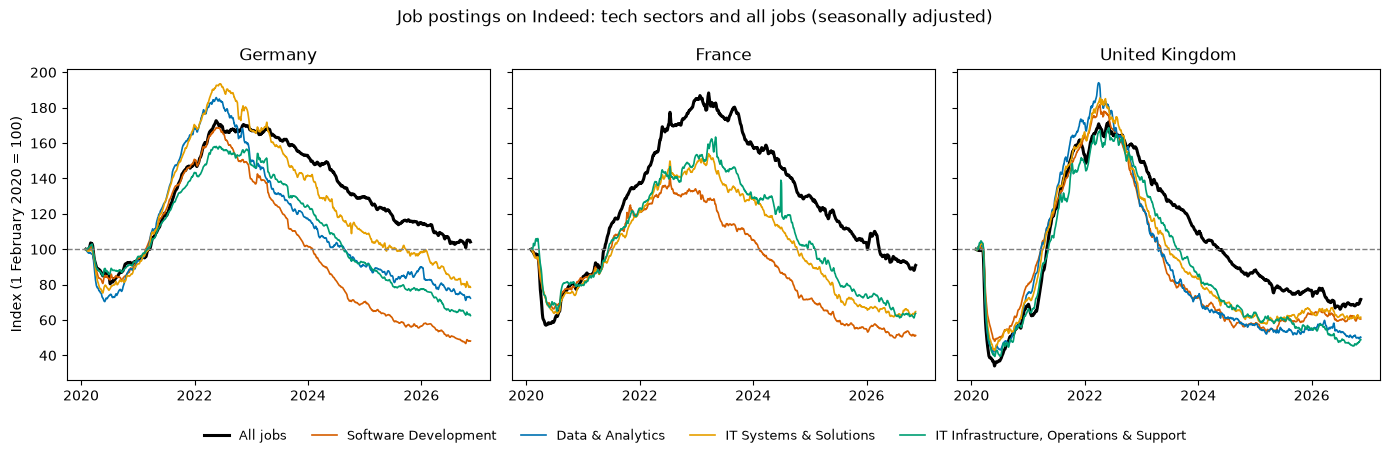

In [41]:
LATEST_DAY = indeed_totals["date"].max()
SERIES_COLOURS = {"All jobs": "#000000", "Software Development": OKABE_ITO[5], "Data & Analytics": OKABE_ITO[4],
                  "IT Systems & Solutions": OKABE_ITO[1], "IT Infrastructure, Operations & Support": OKABE_ITO[3]}

all_jobs = (indeed_totals[indeed_totals["country"].isin(["DE", "FR", "GB"])]
            .rename(columns={"indeed_job_postings_index_SA": "indeed_job_postings_index"})
            .assign(display_name="All jobs"))
postings = pd.concat([all_jobs, indeed_tech])[["date", "country", "display_name", "indeed_job_postings_index"]]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, country in zip(axes, ["DE", "FR", "GB"]):
    for name, colour in SERIES_COLOURS.items():
        series = postings[(postings["country"] == country) & (postings["display_name"] == name)]
        if len(series):
            ax.plot(series["date"], series["indeed_job_postings_index"], color=colour,
                    linewidth=2.2 if name == "All jobs" else 1.2, label=name)
    ax.axhline(100, color="grey", linestyle="--", linewidth=1)
    ax.set_title(COUNTRIES[country])
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].set_ylabel("Index (1 February 2020 = 100)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncols=5, fontsize=9, frameon=False)
fig.suptitle("Job postings on Indeed: tech sectors and all jobs (seasonally adjusted)")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

In [42]:
monthly_postings = (postings.groupby(["country", "display_name", pd.Grouper(key="date", freq="MS")])
                    ["indeed_job_postings_index"].mean())
peaks = []
for (country, name), series in monthly_postings.groupby(level=["country", "display_name"]):
    peak_month = series.idxmax()[2]
    latest = postings.loc[(postings["country"] == country) & (postings["display_name"] == name)
                          & (postings["date"] == LATEST_DAY), "indeed_job_postings_index"].item()
    peaks.append({"country": country, "series": name, "highest month": peak_month.strftime("%Y-%m"),
                  "highest (monthly mean)": series.max(), f"on {LATEST_DAY.date()}": latest,
                  "change from highest (%)": percent_change(series.max(), latest)})
peak_table = pd.DataFrame(peaks).set_index(["country", "series"]).round(1)
peak_table

highest month  \
country series                                                  
DE      All jobs                                      2022-05   
        Data & Analytics                              2022-05   
        IT Infrastructure, Operations & Support       2022-05   
        IT Systems & Solutions                        2022-06   
        Software Development                          2022-05   
FR      All jobs                                      2023-01   
        IT Infrastructure, Operations & Support       2023-04   
        IT Systems & Solutions                        2023-03   
        Software Development                          2022-07   
GB      All jobs                                      2022-05   
        Data & Analytics                              2022-03   
        IT Infrastructure, Operations & Support       2022-06   
        IT Systems & Solutions                        2022-04   
        Software Development                          2022-04   

                                                 highest (monthly mean)  \
country series                                                            
DE      All jobs                                                  171.2   
        Data & Analytics                                          184.5   
        IT Infrastructure, Operations & Support                   157.6   
        IT Systems & Solutions                                    192.8   
        Software Development                                      167.9   
FR      All jobs                                                  185.4   
        IT Infrastructure, Operations & Support                   159.5   
        IT Systems & Solutions                                    150.9   
        Software Development                                      136.6   
GB      All jobs                                                  167.6   
        Data & Analytics                                          187.4   
        IT Infrastructure, Operations & Support                   163.8   
        IT Systems & Solutions                                    183.5   
        Software Development                                      178.2   

                                                 on 2026-11-13  \
country series                                                   
DE      All jobs                                         104.1   
        Data & Analytics                                  72.4   
        IT Infrastructure, Operations & Support           62.5   
        IT Systems & Solutions                            78.6   
        Software Development                              48.1   
FR      All jobs                                          90.9   
        IT Infrastructure, Operations & Support           63.7   
        IT Systems & Solutions                            64.8   
        Software Development                              51.3   
GB      All jobs                                          71.7   
        Data & Analytics                                  50.2   
        IT Infrastructure, Operations & Support           48.9   
        IT Systems & Solutions                            61.6   
        Software Development                              60.6   

                                                 change from highest (%)  
country series                                                            
DE      All jobs                                                   -39.2  
        Data & Analytics                                           -60.8  
        IT Infrastructure, Operations & Support                    -60.4  
        IT Systems & Solutions                                     -59.3  
        Software Development                                       -71.3  
FR      All jobs                                                   -51.0  
        IT Infrastructure, Operations & Support                    -60.0  
        IT Systems & Solutions                                     -57.1  

In [43]:
# did every tech sector fall more from its highest point than all jobs in the same country?
change = peak_table["change from highest (%)"]
for country in ["DE", "FR", "GB"]:
    tech_changes = change[country].drop("All jobs")
    print(f"{country}: all jobs {change[country, 'All jobs']:.1f}%, tech sectors from {tech_changes.max():.1f}% "
          f"to {tech_changes.min():.1f}%, all fell more: {(tech_changes < change[country, 'All jobs']).all()}")

DE: all jobs -39.2%, tech sectors from -59.3% to -71.3%, all fell more: True
FR: all jobs -51.0%, tech sectors from -57.1% to -62.5%, all fell more: True
GB: all jobs -57.2%, tech sectors from -66.0% to -73.2%, all fell more: True


The answer to Q1 is clear in all three countries. Until 2022, tech postings grew together with all postings, and in Germany and the United Kingdom some tech sectors grew even faster. After that, **every tech sector fell more than the job market as a whole**:

* In Germany, all postings are 39.2% below their highest month. The tech sectors are 59.3% to 71.3% lower, and *Software Development* fell the most.
* In France, all postings are 51.0% lower, the tech sectors 57.1% to 62.5%.
* In the United Kingdom, all postings fell by 57.2% and the tech sectors by 66.0% to 73.2%.

On 13 November 2026, *Software Development* stands at 48.1 in Germany and 51.3 in France, so these sectors have about half as many ads as in February 2020. All postings in Germany are still above that level (104.1).

The highest values are monthly means, while the latest values are single days. Indeed's index is already a 7-day average, so one day is not very noisy, but the percentages should be read as rounded figures. The data shows *when* and *how much* tech postings fell, but not *why*. Possible reasons, such as higher interest rates or AI tools, are not tested here.

#### 6.2. ICT employment compared with job postings (Q2) <a class="anchor" id="section_6_2"></a>

Q2 asks if the number of people working in ICT jobs moves in the same direction as the job ads. Only Germany and France have both Indeed tech sectors and Eurostat data after 2019 (section 4.2).

Eurostat counts people (in thousands), and Indeed has an index, so both are rebased to **2022 = 100** with formula (5). I chose 2022 because the Eurostat series has breaks in 2021 for both countries and in 2020 for Germany (section 3.2). From 2022 to 2025 there is no break, so this period gives a fair comparison.

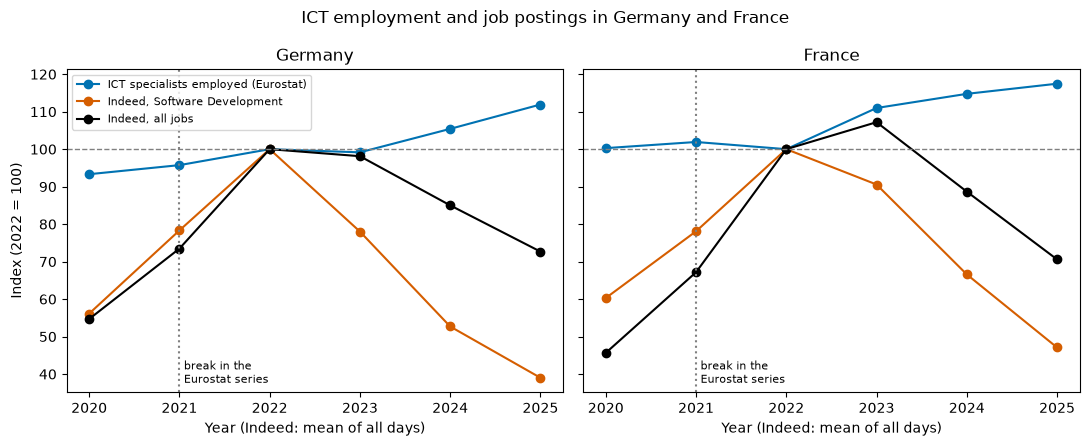

In [44]:
BASE_YEAR = 2022
q2_years = range(2020, 2026)

ict_people = by_country_year(eurostat["ICT specialists"].query("unit == 'THS_PER'"))
indeed_sector_yearly = (indeed_tech.assign(year=indeed_tech["date"].dt.year)
                        .groupby(["country", "display_name", "year"])["indeed_job_postings_index"].mean())

q2_series = {}
for country in ["DE", "FR"]:
    q2_series[country] = pd.DataFrame({
        "ICT specialists employed (Eurostat)": ict_people[country],
        "Indeed, Software Development": indeed_sector_yearly[country, "Software Development"],
        "Indeed, all jobs": indeed_yearly[country],
    }).loc[q2_years].apply(rebase, base=BASE_YEAR)

Q2_COLOURS = {"ICT specialists employed (Eurostat)": OKABE_ITO[4], "Indeed, Software Development": OKABE_ITO[5],
              "Indeed, all jobs": "#000000"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (country, table) in zip(axes, q2_series.items()):
    for column, colour in Q2_COLOURS.items():
        ax.plot(table.index, table[column], marker="o", color=colour, label=column)
    ax.axhline(100, color="grey", linestyle="--", linewidth=1)
    ax.axvline(2021, color="grey", linestyle=":", linewidth=1.5)
    ax.text(2021.05, 0.03, "break in the\nEurostat series", transform=ax.get_xaxis_transform(), fontsize=8)
    ax.set_title(COUNTRIES[country])
    ax.set_xlabel("Year (Indeed: mean of all days)")
axes[0].set_ylabel(f"Index ({BASE_YEAR} = 100)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("ICT employment and job postings in Germany and France")
fig.tight_layout()
plt.show()

In [45]:
q2_changes = {}
for country in ["DE", "FR"]:
    row = {"ICT specialists employed (Eurostat)": percent_change(ict_people[country, 2022], ict_people[country, 2025])}
    for name in TECH_SECTORS + ["All jobs"]:
        yearly = indeed_yearly[country] if name == "All jobs" else indeed_sector_yearly.get((country, name))
        if yearly is not None:
            row[f"Indeed, {name}"] = percent_change(yearly[2022], yearly[2025])
    q2_changes[COUNTRIES[country]] = row
# "-": France has no Data & Analytics sector
pd.DataFrame(q2_changes).map(lambda value: "-" if pd.isna(value) else round(value, 1)).rename_axis(
    columns="change 2022 -> 2025 (%)")

change 2022 -> 2025 (%),Germany,France
ICT specialists employed (Eurostat),11.9,17.5
"Indeed, Software Development",-61.0,-52.9
"Indeed, Data & Analytics",-50.0,-
"Indeed, IT Systems & Solutions",-44.4,-44.1
"Indeed, IT Infrastructure, Operations & Support",-46.2,-38.9
"Indeed, All jobs",-27.3,-29.4


The two sources point in **opposite directions**. From 2022 to 2025, the number of ICT specialists grew by 11.9% in Germany and by 17.5% in France. In the same years, the yearly mean of *Software Development* postings fell by 61.0% and 52.9%, and every other tech sector fell by 38.9% to 50.0%. All postings fell less, by 27.3% and 29.4%.

This is not a contradiction. The two sources measure different things (section 1.4): Eurostat counts the people who **have** an ICT job, while Indeed counts the **open** job ads. Fewer ads mean that employers hire fewer *new* people, but the number of people already in ICT jobs can still grow, for example if fewer of them leave or if hiring continues at a slower pace. The answer to Q2 is therefore "no": in 2022–2025 employment and job ads moved in different directions.

Two limits apply. Indeed is one job site, and its share of the market can change over time. And the years before 2022 cannot be compared in this way because of the breaks in the Eurostat series.

### 7. Roles and languages <a class="anchor" id="chapter7"></a>

This section answers Q3 with the pre-registered test H3, and Q7, which is exploratory.

#### 7.1. Did the mix of roles change between 2023 and 2026? (H3) <a class="anchor" id="section_7_1"></a>

The role groups come from section 4.3. People without a role answer, students and retired people are not counted. The table shows the share of every group in each survey year. H3 compares only 2023 and 2026; 2024 and 2025 are shown to make the path between them visible.

In [46]:
role_counts = pd.DataFrame({year: surveys[year]["role_group"].value_counts() for year in ROLE_YEARS})
role_shares = 100 * role_counts / role_counts.sum()

# rule from section 1.3: every group needs at least 30 answers in both test years
assert (role_counts[[2023, 2026]] >= 30).all().all(), "a role group has fewer than 30 answers"
print("People with a role group:", role_counts.sum().to_dict())
role_shares.round(1).sort_values(2026, ascending=False).rename_axis(columns="share of people (%)")

People with a role group: {2023: 32706, 2024: 22268, 2025: 14218, 2026: 8616}


share of people (%),2023,2024,2025,2026
role_group,,,,
Software development,73.1,71.6,64.8,64.3
Architecture & management,5.6,5.1,13.7,14.9
Other,10.7,11.9,8.7,7.8
Cloud & operations,5.2,5.1,6.0,6.2
Data & AI,4.9,5.7,5.9,5.9
Security,0.6,0.7,0.9,0.8


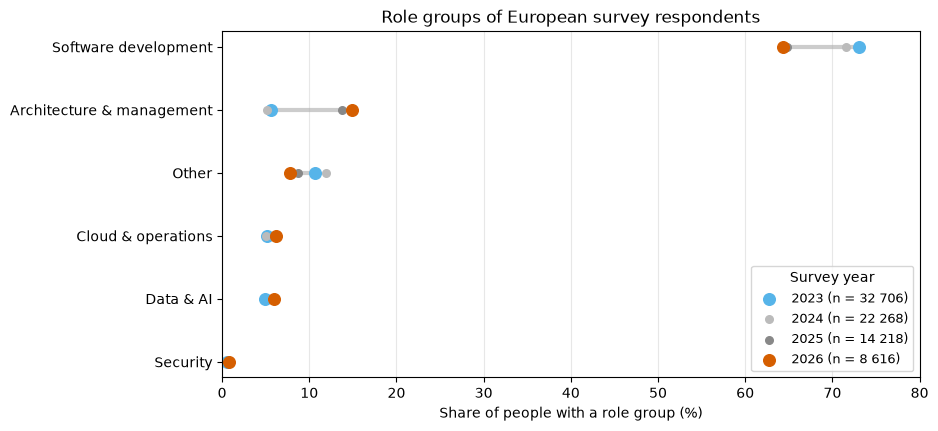

In [47]:
YEAR_COLOURS = {2023: OKABE_ITO[2], 2024: "#BBBBBB", 2025: "#888888", 2026: OKABE_ITO[5]}
order = role_shares[2026].sort_values().index  # largest group at the top

fig, ax = plt.subplots(figsize=(9, 4.5))
for row, group in enumerate(order):
    ax.plot(role_shares.loc[group, [2023, 2026]], [row, row], color="#CCCCCC", linewidth=3, zorder=1)
for year, colour in YEAR_COLOURS.items():
    size = 70 if year in (2023, 2026) else 30
    ax.scatter(role_shares.loc[order, year], range(len(order)), color=colour, s=size, zorder=2,
               label=f"{year} (n = {role_counts[year].sum():,})".replace(",", " "))
ax.set_yticks(range(len(order)), order)
ax.set_xlim(0, 80)
ax.set(title="Role groups of European survey respondents", xlabel="Share of people with a role group (%)")
ax.legend(title="Survey year", loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=0.3)
plt.show()

In [48]:
h3 = chi_square(role_counts[[2023, 2026]].T)
assert (h3["expected"] >= 5).all(), "an expected count is below 5"
scipy_h3 = stats.chi2_contingency(role_counts[[2023, 2026]].T, correction=False)
assert np.isclose(h3["statistic"], scipy_h3.statistic)

print(f"H3: chi2 = {h3['statistic']:.1f}, df = {h3['dof']}, p = {h3['p_value']:.1e}, Cramer's V = {h3['cramers_v']:.3f}")
print("Smallest expected count:", round(h3["expected"].min(), 1))
primary_p_values = {"H3": h3["p_value"]}  # Holm correction for H3-H6 follows in section 8

# the 2023 residuals are the same numbers with the opposite sign
pd.Series(h3["residuals"][1], index=role_counts.index, name="adjusted residual in 2026 (10)").round(1).sort_values()

H3: chi2 = 951.3, df = 5, p = 2.1e-203, Cramer's V = 0.152
Smallest expected count: 56.7


role_group
Software development        -15.9
Other                        -7.8
Security                      2.1
Cloud & operations            3.5
Data & AI                     4.0
Architecture & management    29.3
Name: adjusted residual in 2026 (10), dtype: float64

**Result of H3.** The shares of the role groups in 2026 are different from 2023: $\chi^2 = 951.3$ with 5 degrees of freedom, $p < 0.001$. All expected counts are far above 5, so the test can be used. The Holm correction for all four tests follows in section 8.4. The effect size is $V = 0.152$, between a small (0.1) and a medium (0.3) effect [22].

The adjusted residuals show where the change happened. *Architecture & management* has many more people in 2026 than expected ($z = 29.3$), and *Software development* ($z = -15.9$) and *Other* ($z = -7.8$) have fewer. *Data & AI* and *Cloud & operations* grew a little ($z = 4.0$ and $3.5$).

However, the plot shows something important: *Architecture & management* did not grow slowly. It jumped from 5.1% in 2024 to 13.7% in 2025, exactly the year when the survey added the answer *Architect, software or solutions* (section 4.3). Two extra checks show how much of the result comes from this change:

In [49]:
# extra check 1: the same test without the people who chose the new answer "Architect, software or solutions"
ARCHITECT = "Architect, software or solutions"
without_architects = surveys[2026].loc[surveys[2026]["DevType"] != ARCHITECT, "role_group"].value_counts()
check_1 = chi_square(pd.concat([role_counts[2023], without_architects], axis=1).T)
architects_2026 = (surveys[2026]["DevType"] == ARCHITECT).sum()
management_without = 100 * (role_counts.loc["Architecture & management", 2026] - architects_2026) / role_counts[2026].sum()

# extra check 2: Germany only, so the mix of countries cannot change the result
germany = pd.DataFrame({year: surveys[year].loc[surveys[year]["country"] == "DE", "role_group"].value_counts()
                        for year in [2023, 2026]})
germany = germany[(germany >= 30).all(axis=1)]  # same rule: at least 30 answers per group
check_2 = chi_square(germany.T)

print(f"Architects in 2026: {architects_2026}. Architecture & management without them: {management_without:.1f}% "
      f"(2023: {role_shares.loc['Architecture & management', 2023]:.1f}%)")
print(f"Without architects: p = {check_1['p_value']:.1e}, V = {check_1['cramers_v']:.3f}")
print(f"Germany only ({len(germany)} groups, left out: {sorted(set(role_counts.index) - set(germany.index))}): "
      f"p = {check_2['p_value']:.1e}, V = {check_2['cramers_v']:.3f}")

Architects in 2026: 743. Architecture & management without them: 6.3% (2023: 5.6%)
Without architects: p = 2.8e-24, V = 0.054
Germany only (5 groups, left out: ['Security']): p = 3.9e-33, V = 0.142


* **Without the new answer.** In 2026, 743 people chose *Architect*. Without them, *Architecture & management* has 6.3% of all people with a role group, close to the 5.6% of 2023. The test is still significant, but the effect becomes very small ($V = 0.054$).
* **Germany only.** Inside one country the result is almost the same ($V = 0.142$), so it does not come from a different mix of countries. *Security* is left out here, because it has fewer than 30 answers in Germany.

So H3 is rejected, but the reason matters more than the p-value. **Most of the change in the role mix comes from a change in the survey, not from a change in the job market.** What remains is small: a lower share of *Software development* and *Other*, and slightly larger shares of *Data & AI* and *Cloud & operations*. Even this remainder can come partly from the other new answers of 2025. And because the survey is not a random sample (section 1.4), the shares describe the people who answered, not all developers in Europe.

#### 7.2. Do GitHub and the survey agree on the languages? (Q7) <a class="anchor" id="section_7_2"></a>

The two sources measure language use in different ways. The survey asks people which languages they have worked with in the past year. GitHub counts the developers who pushed code in a language. If both sources show a similar order, it is a good sign that each of them describes real use.

I use 2025, the last year with four quarters of GitHub data. For the survey, the share is computed among the people who answered the language question. For GitHub, I take the mean number of developers per quarter in each country and add the 31 countries together.

In [50]:
LANGUAGE_YEAR = 2025
# survey name -> GitHub name, where only the spelling differs
LANGUAGE_RENAMES = {"Bash/Shell (all shells)": "Shell", "Visual Basic (.Net)": "Visual Basic .NET"}

survey_languages = surveys[LANGUAGE_YEAR]["LanguageHaveWorkedWith"].dropna()
survey_share = (100 * survey_languages.str.split(";").explode().value_counts() / len(survey_languages))
survey_share = survey_share.rename(index=LANGUAGE_RENAMES)

# GitHub: mean number of developers per quarter in each country, added up over the 31 countries
github_year = languages[languages["year"] == LANGUAGE_YEAR]
assert github_year["quarter"].nunique() == 4
github_developers = github_year.groupby(["language", "country"])["num_pushers"].mean().groupby("language").sum()

both = pd.DataFrame({"survey (% of respondents)": survey_share}).join(
    github_developers.rename("GitHub (developers per quarter)"), how="inner")
print(f"Survey respondents who answered: {len(survey_languages)}. Languages in the survey: {len(survey_share)}, "
      f"found on GitHub: {len(both)}")
print("Not matched:", sorted(set(survey_share.index) - set(both.index)))

Survey respondents who answered: 13976. Languages in the survey: 42, found on GitHub: 36
Not matched: ['Delphi', 'HTML/CSS', 'Lisp', 'MicroPython', 'Mojo', 'SQL']


Q7: Spearman rho = 0.923 for 36 languages, permutation p = 0.0002


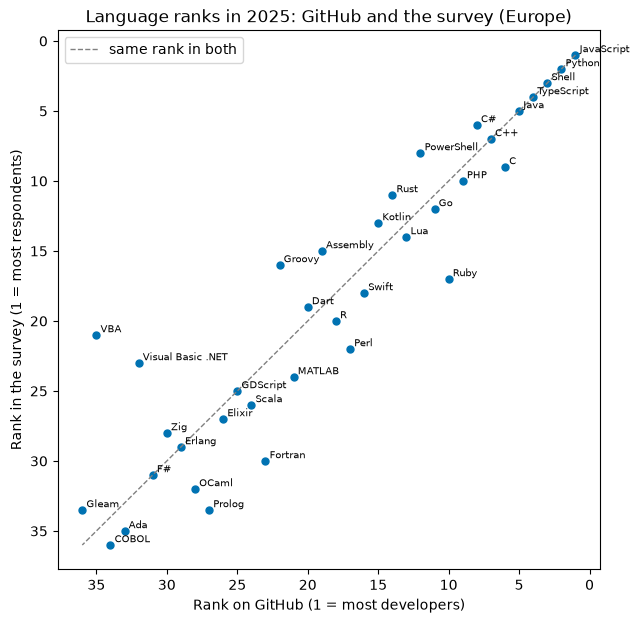

In [51]:
ranks = both.rank(ascending=False)  # rank 1 = most used
rho_q7 = spearman(both.iloc[:, 0], both.iloc[:, 1])
assert np.isclose(rho_q7, stats.spearmanr(both.iloc[:, 0], both.iloc[:, 1]).statistic)
q7_test = stats.permutation_test((both.iloc[:, 0].to_numpy(), both.iloc[:, 1].to_numpy()),
                                 lambda a, b: stats.spearmanr(a, b).statistic, permutation_type="pairings",
                                 n_resamples=RESAMPLES, rng=np.random.default_rng(SEED))
print(f"Q7: Spearman rho = {rho_q7:.3f} for {len(both)} languages, permutation p = {q7_test.pvalue:.4f}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([1, len(both)], [1, len(both)], color="grey", linestyle="--", linewidth=1, label="same rank in both")
ax.scatter(ranks.iloc[:, 1], ranks.iloc[:, 0], color=OKABE_ITO[4], s=25)
for language, (survey_rank, github_rank) in ranks.iterrows():
    ax.annotate(language, (github_rank, survey_rank), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.invert_xaxis()
ax.invert_yaxis()
ax.set(title=f"Language ranks in {LANGUAGE_YEAR}: GitHub and the survey (Europe)",
       xlabel="Rank on GitHub (1 = most developers)", ylabel="Rank in the survey (1 = most respondents)")
ax.legend(loc="upper left")
plt.show()

In [52]:
ranks_table = ranks.rename(columns=lambda name: "rank, " + name.split(" (")[0]).rename_axis("language")
ranks_table["difference"] = ranks_table.iloc[:, 1] - ranks_table.iloc[:, 0]
ranks_table.reindex(ranks_table["difference"].abs().sort_values(ascending=False).index).head(6)

,"rank, survey","rank, GitHub",difference
language,,,
VBA,21.0,35.0,14.0
Visual Basic .NET,23.0,32.0,9.0
Fortran,30.0,23.0,-7.0
Ruby,17.0,10.0,-7.0
Prolog,33.5,27.0,-6.5
Groovy,16.0,22.0,6.0


Six survey languages have no match on GitHub. *HTML/CSS* is one answer in the survey, but two languages on GitHub. *SQL* and *Lisp* exist on GitHub only as separate dialects, for example *TSQL*, *PLpgSQL*, *Common Lisp* and *Emacs Lisp*. *Delphi*, *MicroPython* and *Mojo* do not appear in the GitHub data under these names. I did not try to combine or guess these languages, so they are left out.

For the other 36 languages, the two sources agree very well: $\rho_s = 0.923$. In the permutation test none of the 10 000 shuffles gave such a strong correlation, so $p = 0.0002$ is the smallest value this test can give. The five most used languages are the same, in the same order: JavaScript, Python, Shell, TypeScript and Java.

The largest differences are at the bottom of the list. *VBA* is 21st in the survey but 35th on GitHub, and *Visual Basic .NET* is 23rd and 32nd. One possible reason is that these languages are used for office macros and internal company tools, which are rarely shared as code on GitHub. *Ruby*, *Fortran* and *Prolog* rank higher on GitHub than in the survey. This is a description, not a test of these reasons.

Q7 is exploratory, so it is not part of the Holm correction. Its answer: **yes, the two sources agree on which languages are used most in Europe.**

### 8. Pay, shortage and remote work <a class="anchor" id="chapter8"></a>

_TODO_

### 9. Comparison with a forecast <a class="anchor" id="chapter9"></a>

_TODO_

### 10. Limitations <a class="anchor" id="chapter10"></a>

_TODO_

### 11. Conclusion <a class="anchor" id="chapter11"></a>

_TODO_

### 12. References <a class="anchor" id="chapter12"></a>

1. Indeed Hiring Lab. *Indeed Job Postings Index*. https://github.com/hiring-lab/job_postings_tracker (data under CC BY 4.0, commit `d876002`).
2. Stack Overflow. *Annual Developer Survey*, 2022–2026. https://survey.stackoverflow.co/ (data under ODbL 1.0).
3. Eurostat. *ICT specialists in employment*, dataset `isoc_sks_itspt`. https://ec.europa.eu/eurostat/statistics-explained/index.php/ICT_specialists_in_employment
4. Eurostat. *ICT specialists – statistics on hard-to-fill vacancies in enterprises*, dataset `isoc_ske_itrcrn2`. https://ec.europa.eu/eurostat/statistics-explained/index.php/ICT_specialists_-_statistics_on_hard-to-fill_vacancies_in_enterprises
5. Eurostat. *Purchasing power parities, price level indices, nominal and real expenditures (COICOP 2018)*, dataset `prc_ppp_ind_1`.
6. Eurostat. *Euro/ECU exchange rates – annual data*, dataset `ert_bil_eur_a`.
7. GitHub. *Innovation Graph*. https://github.com/github/innovationgraph (data under CC0 1.0, commit `db6ccdf`).
8. World Economic Forum (2025). *Future of Jobs Report 2025*. Insight Report, January 2025. https://www3.weforum.org/docs/WEF_Future_of_Jobs_Report_2025.pdf
9. Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.
10. Eurostat. *Observation status (flag) code list* `OBS_FLAG`. https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/codelist/ESTAT/OBS_FLAG
11. TitleMax. *50 Cognitive Biases to Be Aware Of So You Can Be the Very Best Version of You* (infographic). Shared in the SoftUni Data Science course materials.
12. Okabe, M. & Ito, K. (2008). *Color Universal Design (CUD): How to make figures and presentations that are friendly to colorblind people*. https://jfly.uni-koeln.de/color/
13. Eurostat. *ICT specialists in employment (isoc_skslf)*, reference metadata, sections 3.2 and 15.2. https://ec.europa.eu/eurostat/cache/metadata/en/isoc_skslf_esms.htm
14. Pearson, K. (1900). On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling. *Philosophical Magazine*, 50(302), 157–175.
15. Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
16. Agresti, A. (2007). *An Introduction to Categorical Data Analysis* (2nd ed.). Wiley.
17. Kruskal, W. H. & Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association*, 47(260), 583–621.
18. Tomczak, M. & Tomczak, E. (2014). The need to report effect size estimates revisited. An overview of some recommended measures of effect size. *Trends in Sport Sciences*, 1(21), 19–25.
19. Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology*, 15(1), 72–101.
20. Efron, B. (1979). Bootstrap methods: another look at the jackknife. *The Annals of Statistics*, 7(1), 1–26.
21. Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261–272.
22. Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2nd ed.). Lawrence Erlbaum Associates.
